# Employee Attrition Prediction Using Machine Learning

**Course:** Predictive Analytics  **Assessment:** CA3  **Programme:** B.Tech Computer Science Engineering

This notebook implements a complete Knowledge Discovery in Databases (KDD) / predictive-modelling workflow that predicts whether an employee is likely to leave an organisation, using the IBM HR Analytics Employee Attrition & Performance dataset.

| # | Stage | # | Stage |
|---|---|---|---|
| 1 | Problem Definition | 8 | Train-Test Split |
| 2 | Data Collection | 9 | Model Development |
| 3 | Data Understanding | 10 | Model Evaluation |
| 4 | Data Cleaning | 11 | Feature Importance and Interpretation |
| 5 | Exploratory Data Analysis | 12 | Final Prediction |
| 6 | Feature Engineering and Selection | 13 | Conclusion and Future Scope |
| 7 | Encoding and Scaling | | |

**How to run:** install the packages in `requirements.txt`, open this notebook (from the repository root or from the `notebooks/` folder), then choose *Kernel → Restart & Run All*. Every result shown below was produced by running the notebook from top to bottom; nothing has been typed in by hand.

> **Responsible-use note.** The dataset is *fictional* (created by IBM data scientists). The models here are an academic exercise. Their outputs are statistical estimates, not facts about any person, and must not be used to make hiring, firing, promotion, or disciplinary decisions about individuals.

## 0. Environment Setup

All imports, the random seed, file paths, and the plotting style are defined once here so that the rest of the notebook is reproducible.

In [1]:
import csv
import platform
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost
from matplotlib.colors import LinearSegmentedColormap
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
                             confusion_matrix, f1_score, fbeta_score, make_scorer, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, StratifiedKFold,
                                     cross_val_predict, cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

# Project module (src/attrition_features.py) holding the feature-engineering function.
# The notebook lives in notebooks/, so the repository root is its parent folder.
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_DIR / "src"))
from attrition_features import ENGINEERED_FEATURES, add_engineered_features

%matplotlib inline

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Paths are relative to the repository root (works from the root or from notebooks/).
DATA_PATH = PROJECT_DIR / "data" / "IBM_HR_Analytics_Employee_Attrition.csv"
FIGURE_DIR = PROJECT_DIR / "visualizations"
RESULTS_DIR = PROJECT_DIR / "results"
MODEL_DIR = PROJECT_DIR / "models"
for folder in (FIGURE_DIR, RESULTS_DIR, MODEL_DIR):
    folder.mkdir(exist_ok=True)

print(f"Python       {platform.python_version()}")
for lib in (pd, np, matplotlib, sns, sklearn, xgboost, joblib):
    print(f"{lib.__name__:<12} {lib.__version__}")

Python       3.13.9
pandas       3.0.6
numpy        2.5.4
matplotlib   3.11.2
seaborn      0.13.2
sklearn      1.9.1
xgboost      3.4.1
joblib       1.6.0


In [2]:
# ---- Plot style: one consistent, colour-blind-checked palette for every chart ----
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
STAYED_COLOR, LEFT_COLOR = "#2a78d6", "#eb6834"          # outcome colours (blue = stayed, orange = left)
MODEL_COLORS = {"Logistic Regression": "#2a78d6", "Random Forest": "#eb6834", "XGBoost": "#1baf7a"}
OUTCOME_PALETTE = {"Stayed": STAYED_COLOR, "Left": LEFT_COLOR}
DIVERGING_CMAP = LinearSegmentedColormap.from_list(
    "blue_gray_red", ["#184f95", "#6da7ec", "#f0efec", "#ef8f8e", "#b8302f"])
SEQUENTIAL_CMAP = LinearSegmentedColormap.from_list(
    "blues", ["#e9f1fc", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "legend.frameon": False, "font.size": 10, "figure.dpi": 100,
})


def save_fig(fig, name):
    """Save a figure to visualizations/ so the report and slides can reuse it."""
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Problem Definition

**Business problem.** When employees leave, an organisation pays for recruitment and onboarding, loses productivity while positions are vacant, and loses knowledge that is hard to replace. HR teams usually learn about a departure only after a resignation is submitted, when it is often too late to address the underlying issue.

**Motivation.** If historical employee records show patterns that distinguish employees who left from those who stayed, a model trained on those records can estimate, for a current employee, how similar their profile is to past leavers. HR can use such estimates to prioritise *supportive* conversations (workload, career development, compensation reviews) at the group level.

**Role of predictive analytics in HR.** Descriptive analytics answers *"what happened?"* (for example, the attrition rate last year). Predictive analytics answers *"what is likely to happen?"* by learning a mapping from inputs to an outcome from historical data and applying it to new cases.

**Machine-learning task.** The intended target is the `Attrition` column. In Stage 3 we verify that it exists and has exactly two values (`Yes`/`No`). Because the target is known for every historical record (labelled data) and takes two values, this is a **supervised binary classification** problem: the model outputs a probability of attrition and a predicted class (`1 = Left`, `0 = Stayed`).

**Objectives.** (1) Understand the data; (2) identify patterns associated with attrition; (3) clean and preprocess the data; (4) perform EDA; (5) engineer and select features; (6) train Logistic Regression, Random Forest, and XGBoost; (7) evaluate and compare them; (8) interpret the predictions; (9) build a reusable prediction function; (10) document the KDD process.

**Expected benefits.** A ranked view of which measured factors are most predictive of attrition in this data, and a reproducible model that converts an employee profile into a risk estimate.

**Limitations known in advance.** The data is fictional and cross-sectional (one snapshot), so the results show *associations*, not causes. A model trained on one (synthetic) organisation may not transfer to another.

**KDD methodology.** Fayyad et al. (1996) describe KDD as the overall process of selection → preprocessing → transformation → data mining → interpretation/evaluation. This notebook follows that process through the 13 stages listed at the top.

## 2. Data Collection

**Source.** *IBM HR Analytics Employee Attrition & Performance*, published on Kaggle by user `pavansubhasht` (https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset). The Kaggle page describes it as *"a fictional data set created by IBM data scientists"*. Kaggle metadata (retrieved October 2026) lists version 1, last updated 2017-03-31, licence *Database: Open Database (ODbL), Contents: Database Contents (DbCL)*. These licences permit redistribution with attribution, which is why a copy is included in `data/`.

**File used.** The copy supplied for this project is **tab-delimited** even though it has a `.csv` extension, whereas the original Kaggle download is comma-delimited. The loader below detects the delimiter automatically, so both versions work.

**Changing the path.**
- *Locally:* keep the file at `data/IBM_HR_Analytics_Employee_Attrition.csv`, or edit `DATA_PATH` in Section 0.
- *Google Colab:* upload the file (Files panel → Upload) and set `DATA_PATH = Path("/content/IBM_HR_Analytics_Employee_Attrition.csv")`. Also upload `src/attrition_features.py` from the repository and add its folder to `sys.path` (it is imported in Section 0). If the data is stored in Google Drive, run `from google.colab import drive; drive.mount("/content/drive")` first and point `DATA_PATH` to the file inside `/content/drive/MyDrive/...`.

In [3]:
def load_dataset(path):
    """Load a delimited text file, detecting whether it uses commas, tabs, or semicolons."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Dataset not found at {path}. Update DATA_PATH in Section 0.")
    with open(path, "r", encoding="utf-8-sig", newline="") as handle:
        delimiter = csv.Sniffer().sniff(handle.read(4096), delimiters=",\t;").delimiter
    return pd.read_csv(path, sep=delimiter, encoding="utf-8-sig"), delimiter


df_raw, detected_delimiter = load_dataset(DATA_PATH)
print(f"File            : {DATA_PATH.name}")
print(f"File size       : {DATA_PATH.stat().st_size:,} bytes")
print(f"Delimiter found : {detected_delimiter!r}")
print(f"Shape           : {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")

File            : IBM_HR_Analytics_Employee_Attrition.csv
File size       : 227,974 bytes
Delimiter found : '\t'
Shape           : 1,470 rows x 35 columns


In [4]:
df_raw.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [5]:
print("Column names:")
print(list(df_raw.columns))
print("\nData types (count of columns per type):")
print(df_raw.dtypes.astype(str).value_counts().to_string())

Column names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Data types (count of columns per type):
int64    26
str       9


**Relevance.** The file contains one row per employee with demographic attributes (age, gender, marital status), job attributes (department, role, level, overtime, travel), compensation (monthly income, salary hike, stock options), tenure (years at the company, in role, since last promotion, with manager), survey-style ratings (job, environment, and relationship satisfaction; work-life balance; job involvement), and the outcome `Attrition`. These are the kinds of variables the problem statement names, so the dataset is suitable for this task. Its main weakness, discussed later, is that it is synthetic.

## 3. Data Understanding

This stage examines the data *before* changing anything: types, statistics, missing values, duplicates, cardinality, the target distribution, identifiers, and possible leakage.

In [6]:
TARGET = "Attrition"

# Verify the target before treating it as one.
assert TARGET in df_raw.columns, f"Expected target column '{TARGET}' is missing."
target_values = sorted(df_raw[TARGET].dropna().unique())
print(f"Target column '{TARGET}' found. Distinct values: {target_values}")
assert set(target_values) == {"No", "Yes"}, "Target is not the expected Yes/No binary variable."
print("Two classes found -> supervised BINARY classification.")

numeric_cols = [c for c in df_raw.columns if pd.api.types.is_numeric_dtype(df_raw[c])]
categorical_cols = [c for c in df_raw.columns if c not in numeric_cols]
print(f"\nRows x columns  : {df_raw.shape}")
print(f"Numeric columns ({len(numeric_cols)}): {numeric_cols}")
print(f"Categorical/text columns ({len(categorical_cols)}): {categorical_cols}")

Target column 'Attrition' found. Distinct values: ['No', 'Yes']
Two classes found -> supervised BINARY classification.

Rows x columns  : (1470, 35)
Numeric columns (26): ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
Categorical/text columns (9): ['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']


In [7]:
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.92,9.14,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.49,403.51,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.19,8.11,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.91,1.02,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.00,0.00,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.87,602.02,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.72,1.09,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.89,20.33,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.73,0.71,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.06,1.11,1.0,1.00,2.0,3.00,5.0


In [8]:
df_raw[categorical_cols].describe().T

,count,unique,top,freq
Attrition,1470,2,No,1233
BusinessTravel,1470,3,Travel_Rarely,1043
Department,1470,3,Research & Development,961
EducationField,1470,6,Life Sciences,606
Gender,1470,2,Male,882
JobRole,1470,9,Sales Executive,326
MaritalStatus,1470,3,Married,673
Over18,1470,1,Y,1470
OverTime,1470,2,No,1054


In [9]:
missing = df_raw.isna().sum()
print(f"Total missing cells: {int(missing.sum())}")
print("Columns with missing values:", missing[missing > 0].to_dict() or "none")

print(f"\nFully duplicated rows                    : {df_raw.duplicated().sum()}")
print(f"Duplicated rows ignoring EmployeeNumber  : {df_raw.drop(columns='EmployeeNumber').duplicated().sum()}")
print(f"EmployeeNumber unique for every row?     : {df_raw['EmployeeNumber'].is_unique}")

Total missing cells: 0
Columns with missing values: none

Fully duplicated rows                    : 0
Duplicated rows ignoring EmployeeNumber  : 0
EmployeeNumber unique for every row?     : True


In [10]:
cardinality = (pd.DataFrame({"dtype": df_raw.dtypes.astype(str), "n_unique": df_raw.nunique()})
               .sort_values("n_unique"))
constant_cols = cardinality.index[cardinality["n_unique"] == 1].tolist()
id_like_cols = [c for c in df_raw.columns if df_raw[c].is_unique and c != TARGET]
print("Constant columns (one value only):", constant_cols)
for c in constant_cols:
    print(f"   {c}: {df_raw[c].iloc[0]}")
print("Identifier-like columns (unique per row):", id_like_cols)
cardinality.T

Constant columns (one value only): ['Over18', 'StandardHours', 'EmployeeCount']
   Over18: Y
   StandardHours: 80
   EmployeeCount: 1
Identifier-like columns (unique per row): ['EmployeeNumber']


,Over18,StandardHours,EmployeeCount,Gender,Attrition,PerformanceRating,OverTime,MaritalStatus,Department,BusinessTravel,...,YearsInCurrentRole,DistanceFromHome,YearsAtCompany,TotalWorkingYears,Age,HourlyRate,DailyRate,MonthlyIncome,MonthlyRate,EmployeeNumber
dtype,str,int64,int64,str,str,int64,str,str,str,str,...,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64
n_unique,1,1,1,2,2,2,2,3,3,3,...,19,29,37,40,43,71,886,1349,1427,1470


In [11]:
target_counts = df_raw[TARGET].value_counts()
target_share = df_raw[TARGET].value_counts(normalize=True).mul(100).round(2)
print(pd.DataFrame({"count": target_counts, "percent": target_share}).to_string())
imbalance_ratio = target_counts["No"] / target_counts["Yes"]
print(f"\nImbalance ratio (No : Yes) = {imbalance_ratio:.2f} : 1")
print(f"A model that always predicts 'No' would be {target_share['No']:.1f}% accurate "
      "while identifying zero leavers.")

           count  percent
Attrition                
No          1233    83.88
Yes          237    16.12

Imbalance ratio (No : Yes) = 5.20 : 1
A model that always predicts 'No' would be 83.9% accurate while identifying zero leavers.


### 3.1 Data dictionary

Meanings marked *documented* are taken from the coding table on the dataset's Kaggle page. All other descriptions are inferred from the column name only and are marked *not documented*. In particular, the source does not define `DailyRate`, `HourlyRate` and `MonthlyRate`, the units of `DistanceFromHome`, or the currency of `MonthlyIncome`.

In [12]:
DATA_DICTIONARY = {
    "Age": "Employee age in years",
    "Attrition": "Whether the employee left the organisation (Yes/No)",
    "BusinessTravel": "Business-travel frequency (Non-Travel / Travel_Rarely / Travel_Frequently)",
    "DailyRate": "Pay-rate field; exact definition not documented",
    "Department": "Department (Sales / Research & Development / Human Resources)",
    "DistanceFromHome": "Distance from home to work; units not documented",
    "Education": "Documented: 1 Below College, 2 College, 3 Bachelor, 4 Master, 5 Doctor",
    "EducationField": "Field of education",
    "EmployeeCount": "Employee count per record (constant = 1)",
    "EmployeeNumber": "Unique employee identifier",
    "EnvironmentSatisfaction": "Documented: 1 Low, 2 Medium, 3 High, 4 Very High",
    "Gender": "Gender (Female / Male)",
    "HourlyRate": "Pay-rate field; exact definition not documented",
    "JobInvolvement": "Documented: 1 Low, 2 Medium, 3 High, 4 Very High",
    "JobLevel": "Job level 1-5; scale not documented (higher appears more senior)",
    "JobRole": "Job role (9 roles)",
    "JobSatisfaction": "Documented: 1 Low, 2 Medium, 3 High, 4 Very High",
    "MaritalStatus": "Marital status (Single / Married / Divorced)",
    "MonthlyIncome": "Monthly income; currency not documented",
    "MonthlyRate": "Pay-rate field; exact definition not documented",
    "NumCompaniesWorked": "Number of companies worked at; whether it includes the current one is not documented",
    "Over18": "Whether the employee is over 18 (constant = 'Y')",
    "OverTime": "Whether the employee works overtime (Yes/No)",
    "PercentSalaryHike": "Most recent salary increase in percent (inferred from name)",
    "PerformanceRating": "Documented: 1 Low, 2 Good, 3 Excellent, 4 Outstanding",
    "RelationshipSatisfaction": "Documented: 1 Low, 2 Medium, 3 High, 4 Very High",
    "StandardHours": "Standard hours (constant = 80; period not documented)",
    "StockOptionLevel": "Stock-option level 0-3; meaning of levels not documented",
    "TotalWorkingYears": "Total years of work experience",
    "TrainingTimesLastYear": "Number of training sessions in the last year",
    "WorkLifeBalance": "Documented: 1 Bad, 2 Good, 3 Better, 4 Best",
    "YearsAtCompany": "Years at the current company",
    "YearsInCurrentRole": "Years in the current role",
    "YearsSinceLastPromotion": "Years since the last promotion",
    "YearsWithCurrManager": "Years with the current manager",
}
ORDINAL_COLS = ["Education", "EnvironmentSatisfaction", "JobInvolvement", "JobLevel", "JobSatisfaction",
                "PerformanceRating", "RelationshipSatisfaction", "StockOptionLevel", "WorkLifeBalance"]


def column_role(col):
    if col == TARGET:
        return "Target"
    if col in id_like_cols:
        return "Identifier - drop"
    if col in constant_cols:
        return "Constant - drop"
    if col in ORDINAL_COLS:
        return "Feature (ordinal, coded 1..k)"
    return "Feature (numeric)" if col in numeric_cols else "Feature (categorical)"


missing_from_dictionary = set(df_raw.columns) - set(DATA_DICTIONARY)
assert not missing_from_dictionary, f"Undocumented columns: {missing_from_dictionary}"
data_dictionary = pd.DataFrame({
    "Column": df_raw.columns,
    "Type": df_raw.dtypes.astype(str).values,
    "Unique": df_raw.nunique().values,
    "Example": df_raw.iloc[0].astype(str).values,
    "Meaning": [DATA_DICTIONARY[c] for c in df_raw.columns],
    "Role in model": [column_role(c) for c in df_raw.columns],
})
data_dictionary.to_csv(RESULTS_DIR / "data_dictionary.csv", index=False)
with pd.option_context("display.max_colwidth", 90):
    display(data_dictionary)

,Column,Type,Unique,Example,Meaning,Role in model
0,Age,int64,43,41,Employee age in years,Feature (numeric)
1,Attrition,str,2,Yes,Whether the employee left the organisation (Yes/No),Target
2,BusinessTravel,str,3,Travel_Rarely,Business-travel frequency (Non-Travel / Travel_Rarely / Travel_Frequently),Feature (categorical)
3,DailyRate,int64,886,1102,Pay-rate field; exact definition not documented,Feature (numeric)
4,Department,str,3,Sales,Department (Sales / Research & Development / Human Resources),Feature (categorical)
5,DistanceFromHome,int64,29,1,Distance from home to work; units not documented,Feature (numeric)
6,Education,int64,5,2,"Documented: 1 Below College, 2 College, 3 Bachelor, 4 Master, 5 Doctor","Feature (ordinal, coded 1..k)"
7,EducationField,str,6,Life Sciences,Field of education,Feature (categorical)
8,EmployeeCount,int64,1,1,Employee count per record (constant = 1),Constant - drop
9,EmployeeNumber,int64,1470,1,Unique employee identifier,Identifier - drop


In [13]:
# First look at plausible relationships: mean of each numeric feature for leavers vs stayers.
numeric_features_raw = [c for c in numeric_cols if c not in constant_cols + id_like_cols]
group_means = df_raw.groupby(TARGET)[numeric_features_raw].mean().T
group_means["Difference (Yes - No)"] = group_means["Yes"] - group_means["No"]
group_means["Relative difference %"] = 100 * group_means["Difference (Yes - No)"] / group_means["No"]
group_means.sort_values("Relative difference %").round(2)

Attrition,No,Yes,Difference (Yes - No),Relative difference %
StockOptionLevel,0.85,0.53,-0.32,-37.59
YearsInCurrentRole,4.48,2.90,-1.58,-35.26
YearsWithCurrManager,4.37,2.85,-1.52,-34.69
TotalWorkingYears,11.86,8.24,-3.62,-30.50
YearsAtCompany,7.37,5.13,-2.24,-30.37
MonthlyIncome,6832.74,4787.09,-2045.65,-29.94
JobLevel,2.15,1.64,-0.51,-23.71
YearsSinceLastPromotion,2.23,1.95,-0.29,-12.94
JobSatisfaction,2.78,2.47,-0.31,-11.17
EnvironmentSatisfaction,2.77,2.46,-0.31,-11.08


### 3.2 Identifiers and potential data leakage

**Data leakage** happens when a model is trained on information that would not be available when a prediction is actually made, or that encodes the answer. Leakage makes test scores look better than real-world performance.

- `EmployeeNumber` is a unique ID. It carries no generalisable information, and if it were correlated with attrition (for example through hiring order) the pattern would be spurious. It is dropped.
- None of the columns is an obvious post-exit record such as an exit-interview score or termination date.
- **Subtle risk: snapshot timing.** The data is a single snapshot. For leavers, values such as `YearsAtCompany`, `YearsInCurrentRole` and `MonthlyIncome` probably describe the employee *at the time they left*, while for current staff they describe them *now*. The source does not document when each value was recorded. Tenure-type features may therefore behave differently on genuinely new predictions. This cannot be fixed with this dataset and is listed as a limitation.
- **Preprocessing leakage** (fitting scalers or encoders on all data) is prevented by putting every learned transformation inside a scikit-learn `Pipeline` that is fitted on the training split only (Stages 7–9).

**Interpretation – data understanding.**
- The file has **1,470 employees × 35 columns** (26 integer, 9 text). It has **no missing values** and **no duplicate rows**, even when the ID column is ignored.
- `Attrition` has two classes: **1,233 No (83.9%)** and **237 Yes (16.1%)**, an imbalance of about **5.2 : 1**. A model that always answers "No" would already be 83.9% accurate, so accuracy cannot be the main metric.
- `EmployeeCount` (always 1), `Over18` (always "Y") and `StandardHours` (always 80) carry no information. `EmployeeNumber` is a unique identifier. All four are removed in Stage 4.
- Leavers differ most from stayers (relative difference of means) in **stock-option level (−38%)**, **years in current role / with current manager / at the company and total working years (−30% to −35%)**, **monthly income (4,787 vs 6,833, −30%)** and **job level (−24%)**. They are also younger on average (33.6 vs 37.6 years) and live further from work (+19%). Pay-rate fields, salary hike and performance rating show almost no difference.
- These are one-variable-at-a-time comparisons. Several of these variables move together (older employees have more experience, higher levels and higher pay), so they are not independent findings.

## 4. Data Cleaning

Every check is reported, including checks that find nothing, and every change is logged. Outliers are investigated but **not** deleted automatically.

In [14]:
df_clean = df_raw.copy()
shape_before = df_clean.shape
cleaning_log = []

# 4.1 Missing values
n_missing = int(df_clean.isna().sum().sum())
cleaning_log.append(("Missing values", f"{n_missing} missing cells found",
                     "No imputation needed; imputers are still kept in the pipeline for unseen input"))

# 4.2 Duplicates
n_dup = int(df_clean.duplicated().sum())
n_dup_no_id = int(df_clean.drop(columns=id_like_cols).duplicated().sum())
cleaning_log.append(("Duplicate records", f"{n_dup} exact duplicates; {n_dup_no_id} ignoring the ID",
                     "Nothing removed"))

# 4.3 Text consistency: stray whitespace or inconsistent capitalisation in categories
for col in categorical_cols:
    values = df_clean[col].astype(str)
    stripped = values.str.strip()
    assert (values == stripped).all(), f"Whitespace issue in {col}"
    assert stripped.str.lower().nunique() == stripped.nunique(), f"Case-inconsistent labels in {col}"
cleaning_log.append(("Category labels", "No whitespace or capitalisation inconsistencies", "Nothing changed"))
print("Category label checks passed.")

Category label checks passed.


In [15]:
# 4.4 Invalid-value checks: documented scales, non-negativity, plausible age range
documented_ranges = {"Education": (1, 5), "EnvironmentSatisfaction": (1, 4), "JobInvolvement": (1, 4),
                     "JobSatisfaction": (1, 4), "PerformanceRating": (1, 4),
                     "RelationshipSatisfaction": (1, 4), "WorkLifeBalance": (1, 4)}
range_report = []
for col, (low, high) in documented_ranges.items():
    out_of_range = int((~df_clean[col].between(low, high)).sum())
    range_report.append((col, f"{low}-{high}", df_clean[col].min(), df_clean[col].max(), out_of_range))
range_report = pd.DataFrame(range_report, columns=["Column", "Documented range", "Min", "Max", "Out of range"])
display(range_report)

negative_counts = (df_clean[numeric_cols] < 0).sum()
print(f"Columns with negative values: {negative_counts[negative_counts > 0].to_dict() or 'none'}")
print(f"Age range: {df_clean['Age'].min()}-{df_clean['Age'].max()}")
print("PerformanceRating values present:", df_clean["PerformanceRating"].value_counts().sort_index().to_dict())
cleaning_log.append(("Invalid values", "All coded scales within documented ranges; no negatives; age 18-60",
                     "Nothing changed"))

,Column,Documented range,Min,Max,Out of range
0,Education,1-5,1,5,0
1,EnvironmentSatisfaction,1-4,1,4,0
2,JobInvolvement,1-4,1,4,0
3,JobSatisfaction,1-4,1,4,0
4,PerformanceRating,1-4,3,4,0
5,RelationshipSatisfaction,1-4,1,4,0
6,WorkLifeBalance,1-4,1,4,0


Columns with negative values: none
Age range: 18-60
PerformanceRating values present: {3: 1244, 4: 226}


In [16]:
# 4.5 Logical consistency between related columns
consistency_rules = {
    "YearsAtCompany <= TotalWorkingYears": df_clean["YearsAtCompany"] <= df_clean["TotalWorkingYears"],
    "YearsInCurrentRole <= YearsAtCompany": df_clean["YearsInCurrentRole"] <= df_clean["YearsAtCompany"],
    "YearsWithCurrManager <= YearsAtCompany": df_clean["YearsWithCurrManager"] <= df_clean["YearsAtCompany"],
    "YearsSinceLastPromotion <= YearsAtCompany": df_clean["YearsSinceLastPromotion"] <= df_clean["YearsAtCompany"],
    "Age - TotalWorkingYears >= 14": (df_clean["Age"] - df_clean["TotalWorkingYears"]) >= 14,
}
consistency = pd.DataFrame({"Rule": list(consistency_rules),
                            "Violations": [int((~ok).sum()) for ok in consistency_rules.values()]})
display(consistency)

zero_companies = df_clean[df_clean["NumCompaniesWorked"] == 0]
pattern = (zero_companies["TotalWorkingYears"] == zero_companies["YearsAtCompany"] + 1).sum()
print(f"Rows with NumCompaniesWorked == 0: {len(zero_companies)}")
print(f"  ...of which TotalWorkingYears == YearsAtCompany + 1: {pattern}")
cleaning_log.append(("Consistency rules", f"0 violations of {len(consistency_rules)} rules",
                     "Nothing changed"))
cleaning_log.append(("NumCompaniesWorked = 0", f"{len(zero_companies)} rows, all with TotalWorkingYears = YearsAtCompany + 1",
                     "Kept as-is; documented as an undocumented coding convention"))

,Rule,Violations
0,YearsAtCompany <= TotalWorkingYears,0
1,YearsInCurrentRole <= YearsAtCompany,0
2,YearsWithCurrManager <= YearsAtCompany,0
3,YearsSinceLastPromotion <= YearsAtCompany,0
4,Age - TotalWorkingYears >= 14,0


Rows with NumCompaniesWorked == 0: 197
  ...of which TotalWorkingYears == YearsAtCompany + 1: 197


**About `NumCompaniesWorked = 0`.** Taken literally, "worked at zero companies" contradicts having a job. In every such row `TotalWorkingYears` is exactly `YearsAtCompany + 1`. This regular pattern suggests a coding convention of the synthetic data generator rather than random entry errors. Recoding it would mean guessing the generator's intent, so the values are kept unchanged and the ambiguity is recorded.

,IQR outliers,Percent,Upper fence,Max
TrainingTimesLastYear,238,16.2,4.5,6
MonthlyIncome,114,7.8,16581.0,19999
YearsSinceLastPromotion,107,7.3,7.5,15
YearsAtCompany,104,7.1,18.0,40
TotalWorkingYears,63,4.3,28.5,40
NumCompaniesWorked,52,3.5,8.5,9
YearsInCurrentRole,21,1.4,14.5,18
YearsWithCurrManager,14,1.0,14.5,17


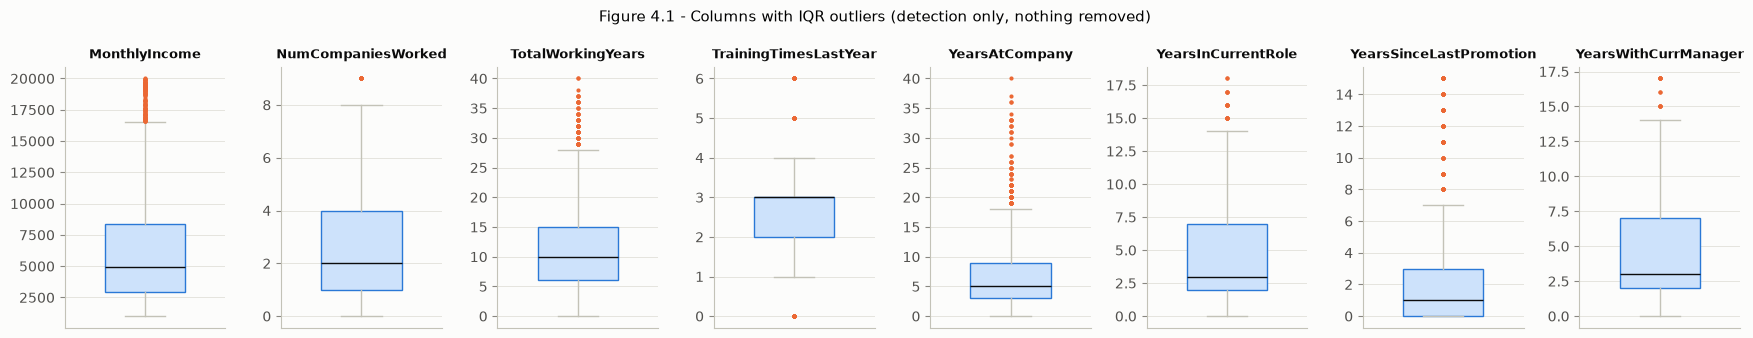

In [17]:
# 4.6 Outlier analysis using the 1.5 x IQR rule (detection only)
continuous_cols = ["Age", "DailyRate", "DistanceFromHome", "HourlyRate", "MonthlyIncome", "MonthlyRate",
                   "NumCompaniesWorked", "PercentSalaryHike", "TotalWorkingYears", "TrainingTimesLastYear",
                   "YearsAtCompany", "YearsInCurrentRole", "YearsSinceLastPromotion", "YearsWithCurrManager"]
q1, q3 = df_clean[continuous_cols].quantile(0.25), df_clean[continuous_cols].quantile(0.75)
iqr = q3 - q1
outlier_counts = ((df_clean[continuous_cols] < q1 - 1.5 * iqr) | (df_clean[continuous_cols] > q3 + 1.5 * iqr)).sum()
outlier_table = pd.DataFrame({"IQR outliers": outlier_counts,
                              "Percent": (100 * outlier_counts / len(df_clean)).round(1),
                              "Upper fence": (q3 + 1.5 * iqr).round(1),
                              "Max": df_clean[continuous_cols].max()})
display(outlier_table[outlier_table["IQR outliers"] > 0].sort_values("IQR outliers", ascending=False))

flagged = outlier_table.index[outlier_table["IQR outliers"] > 0].tolist()
fig, axes = plt.subplots(1, len(flagged), figsize=(2.2 * len(flagged), 3.4))
for ax, col in zip(axes, flagged):
    ax.boxplot(df_clean[col], widths=0.5, patch_artist=True,
               boxprops=dict(facecolor="#cde2fb", edgecolor=STAYED_COLOR),
               medianprops=dict(color=INK), whiskerprops=dict(color=AXIS), capprops=dict(color=AXIS),
               flierprops=dict(marker="o", markersize=3, markerfacecolor=LEFT_COLOR, markeredgecolor="none"))
    ax.set_title(col, fontsize=9)
    ax.set_xticks([])
fig.suptitle("Figure 4.1 - Columns with IQR outliers (detection only, nothing removed)", fontsize=11)
fig.tight_layout()
save_fig(fig, "fig_4_1_outliers")
plt.show()

In [18]:
# Are the high-income "outliers" plausible? Compare with job level.
high_income = df_clean["MonthlyIncome"] > (q3 + 1.5 * iqr)["MonthlyIncome"]
print("Job level of employees flagged as MonthlyIncome outliers:")
print(df_clean.loc[high_income, "JobLevel"].value_counts().sort_index().to_string())
print(f"\nMedian income by job level:\n{df_clean.groupby('JobLevel')['MonthlyIncome'].median().to_string()}")
cleaning_log.append(("Outliers (IQR rule)", f"{int(outlier_counts.sum())} flagged values in {len(flagged)} columns",
                     "Kept: values are plausible (senior levels, long tenure), not data errors"))

Job level of employees flagged as MonthlyIncome outliers:
JobLevel
4    45
5    69

Median income by job level:
JobLevel
1     2670.0
2     5340.0
3     9980.0
4    16154.0
5    19232.0


In [19]:
# 4.7 Remove constant and identifier columns, 4.8 validate and encode the target
columns_to_drop = constant_cols + id_like_cols
df_clean = df_clean.drop(columns=columns_to_drop)
cleaning_log.append(("Constant columns", ", ".join(constant_cols), "Dropped: zero variance, no information"))
cleaning_log.append(("Identifier column", ", ".join(id_like_cols), "Dropped: unique ID, not a predictor"))

df_clean[TARGET] = df_clean[TARGET].map({"Yes": 1, "No": 0})
assert df_clean[TARGET].isna().sum() == 0 and set(df_clean[TARGET].unique()) == {0, 1}
cleaning_log.append(("Target label", "Yes/No validated", "Encoded as 1 = Left (Yes), 0 = Stayed (No)"))

print(f"Shape before cleaning: {shape_before}")
print(f"Shape after cleaning : {df_clean.shape}  ({shape_before[1] - df_clean.shape[1]} columns dropped, "
      f"{shape_before[0] - df_clean.shape[0]} rows dropped)")
cleaning_summary = pd.DataFrame(cleaning_log, columns=["Check", "Finding", "Action"])
cleaning_summary.to_csv(RESULTS_DIR / "cleaning_log.csv", index=False)
with pd.option_context("display.max_colwidth", 100):
    display(cleaning_summary)

Shape before cleaning: (1470, 35)
Shape after cleaning : (1470, 31)  (4 columns dropped, 0 rows dropped)


,Check,Finding,Action
0,Missing values,0 missing cells found,No imputation needed; imputers are still kept in the pipeline for unseen input
1,Duplicate records,0 exact duplicates; 0 ignoring the ID,Nothing removed
2,Category labels,No whitespace or capitalisation inconsistencies,Nothing changed
3,Invalid values,All coded scales within documented ranges; no negatives; age 18-60,Nothing changed
4,Consistency rules,0 violations of 5 rules,Nothing changed
5,NumCompaniesWorked = 0,"197 rows, all with TotalWorkingYears = YearsAtCompany + 1",Kept as-is; documented as an undocumented coding convention
6,Outliers (IQR rule),713 flagged values in 8 columns,"Kept: values are plausible (senior levels, long tenure), not data errors"
7,Constant columns,"Over18, StandardHours, EmployeeCount","Dropped: zero variance, no information"
8,Identifier column,EmployeeNumber,"Dropped: unique ID, not a predictor"
9,Target label,Yes/No validated,"Encoded as 1 = Left (Yes), 0 = Stayed (No)"


**Interpretation – data cleaning.**
- **No rows were removed.** Four columns were dropped (three constant, one identifier), giving **1,470 × 31**, and the target was encoded as 1 = Left, 0 = Stayed.
- The IQR rule flags 713 values in 8 columns, but none of them looks like an error:
  - `TrainingTimesLastYear` is flagged 238 times only because its IQR is 1. Values of 0, 5 or 6 training sessions are ordinary counts.
  - All 114 `MonthlyIncome` "outliers" are at **job level 4 or 5**, whose median incomes are 16,154 and 19,232. They are senior employees, not anomalies. Removing them would delete most of the senior staff and bias the model.
  - Long tenures (up to 40 years) agree with ages up to 60 and pass every consistency rule.
- `PerformanceRating` only takes the values 3 and 4, so it can carry little information.
- The `NumCompaniesWorked = 0` pattern is kept and documented, not "corrected".

## 5. Exploratory Data Analysis (EDA)

**How rates are calculated.** For a grouping variable, the attrition rate of a group is *(leavers in the group) ÷ (all employees in the group)*. It is **not** the group's share of all leavers. This makes groups of different sizes comparable. Small groups give unstable rates, so every bar shows the group size *n* and a 95% Wilson confidence interval. The dashed line marks the overall attrition rate.

**Association is not causation.** A higher rate in a group shows an association in this snapshot. It does not show that the attribute *causes* people to leave, because other variables (confounders) may explain the difference.

In [20]:
eda = df_clean.copy()
eda["Outcome"] = eda[TARGET].map({0: "Stayed", 1: "Left"})
OVERALL_RATE = eda[TARGET].mean()

LEVEL_LABELS = {
    "JobSatisfaction": {1: "1 Low", 2: "2 Medium", 3: "3 High", 4: "4 Very High"},
    "EnvironmentSatisfaction": {1: "1 Low", 2: "2 Medium", 3: "3 High", 4: "4 Very High"},
    "JobInvolvement": {1: "1 Low", 2: "2 Medium", 3: "3 High", 4: "4 Very High"},
    "WorkLifeBalance": {1: "1 Bad", 2: "2 Good", 3: "3 Better", 4: "4 Best"},
}


def wilson_interval(successes, n, z=1.96):
    """95% Wilson score interval for a proportion (more reliable than p +/- 1.96*SE for small n)."""
    p = successes / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half


def attrition_rate_table(data, col, order=None):
    table = data.groupby(col, observed=True)[TARGET].agg(leavers="sum", employees="count")
    if order is not None:
        table = table.reindex(order)
    table["rate"] = table["leavers"] / table["employees"]
    table["ci_low"], table["ci_high"] = wilson_interval(table["leavers"], table["employees"])
    return table


def plot_attrition_rate(ax, data, col, title, order=None, labels=None, sort=False):
    table = attrition_rate_table(data, col, order)
    if sort:
        table = table.sort_values("rate")
    names = [str(labels.get(i, i)) if labels else str(i) for i in table.index]
    y = np.arange(len(table))
    err = np.vstack([table["rate"] - table["ci_low"], table["ci_high"] - table["rate"]])
    ax.barh(y, table["rate"] * 100, height=0.6, color=LEFT_COLOR, zorder=2)
    ax.errorbar(table["rate"] * 100, y, xerr=err * 100, fmt="none", ecolor=INK_2, elinewidth=1, capsize=3, zorder=3)
    ax.axvline(OVERALL_RATE * 100, color=MUTED, linestyle="--", linewidth=1, zorder=1)
    for yi, (rate, high, n) in enumerate(zip(table["rate"], table["ci_high"], table["employees"])):
        ax.text(high * 100 + 1, yi, f"{rate:.1%}  (n={n})", va="center", fontsize=8.5, color=INK_2)
    ax.set_yticks(y, names)
    ax.set_xlim(0, max(table["ci_high"].max() * 100 + 16, 30))
    ax.set_xlabel("Attrition rate (%)  - dashed line = overall rate")
    ax.set_title(title, loc="left")
    ax.grid(axis="y", visible=False)
    return table

### 5.1 Attrition class distribution

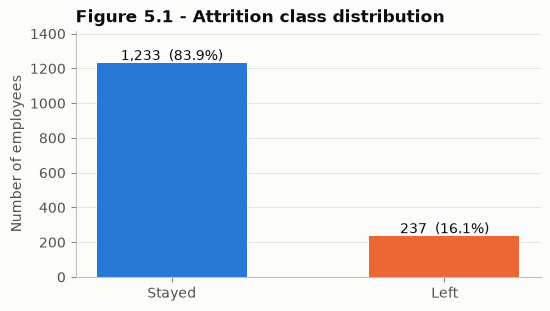

In [21]:
fig, ax = plt.subplots(figsize=(6, 3.2))
counts = eda["Outcome"].value_counts().reindex(["Stayed", "Left"])
bars = ax.bar(counts.index, counts.values, color=[STAYED_COLOR, LEFT_COLOR], width=0.55, zorder=2)
for bar, value in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 15, f"{value:,}  ({value / counts.sum():.1%})",
            ha="center", fontsize=10, color=INK)
ax.set_ylabel("Number of employees")
ax.set_ylim(0, counts.max() * 1.15)
ax.set_title("Figure 5.1 - Attrition class distribution", loc="left")
ax.grid(axis="x", visible=False)
save_fig(fig, "fig_5_1_class_distribution")
plt.show()

**Observation.** 1,233 employees stayed (83.9%) and 237 left (16.1%). Because of this imbalance the project uses stratified splitting, class-weighted models, and recall/precision/F1/ROC-AUC rather than accuracy alone.

### 5.2 Attrition by age group

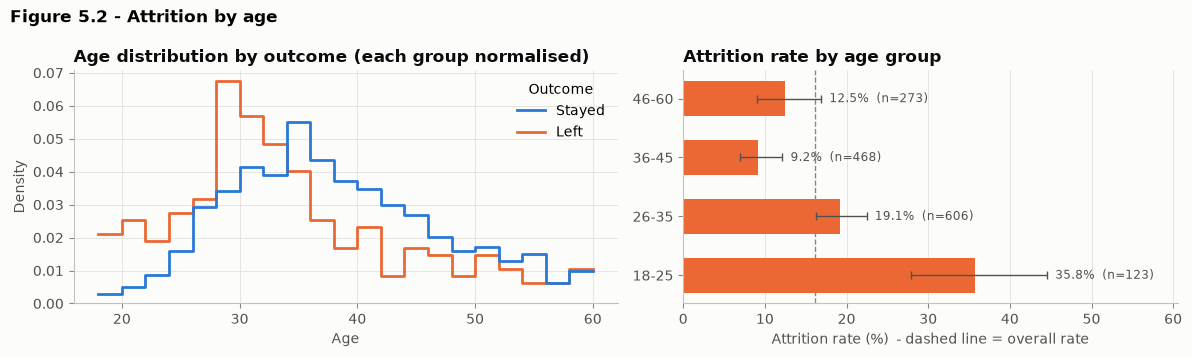

In [22]:
eda["AgeGroup"] = pd.cut(eda["Age"], bins=[17, 25, 35, 45, 60], labels=["18-25", "26-35", "36-45", "46-60"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.1, 1]})
sns.histplot(data=eda, x="Age", hue="Outcome", hue_order=["Stayed", "Left"], palette=OUTCOME_PALETTE,
             bins=range(18, 62, 2), stat="density", common_norm=False, element="step", fill=False,
             linewidth=2, ax=axes[0])
axes[0].set_title("Age distribution by outcome (each group normalised)", loc="left")
axes[0].set_ylabel("Density")
plot_attrition_rate(axes[1], eda, "AgeGroup", "Attrition rate by age group")
fig.suptitle("Figure 5.2 - Attrition by age", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig_5_2_age")
plt.show()

**Observation.** Attrition falls sharply with age. It is **35.8%** for ages 18–25 (n = 123) and **19.1%** for 26–35, against **9.2%** for 36–45 and **12.5%** for 46–60. The median leaver is 32 years old versus 36 for stayers. Age is strongly linked to experience, job level and income, so this pattern probably reflects career stage at least partly, not age itself.

### 5.3 Attrition by department and 5.4 by job role

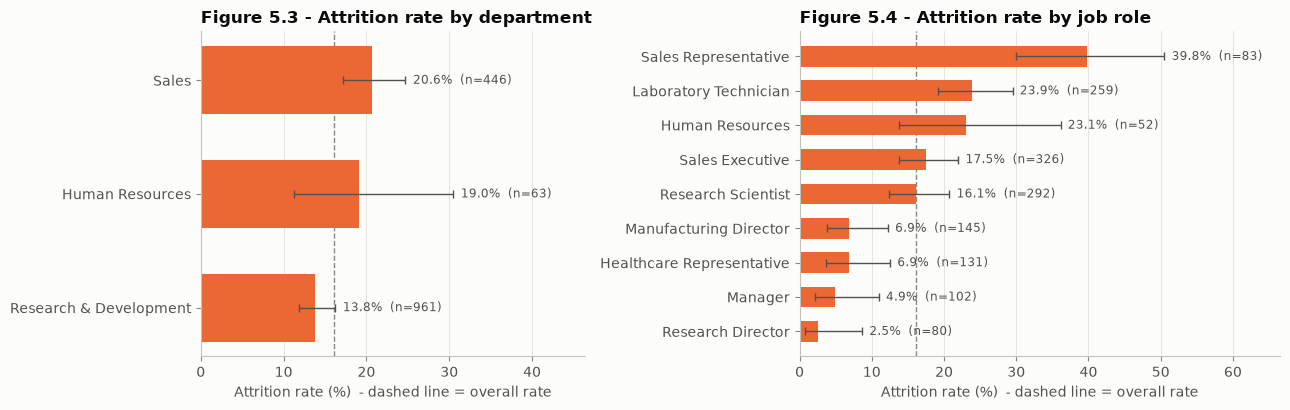

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
plot_attrition_rate(axes[0], eda, "Department", "Figure 5.3 - Attrition rate by department", sort=True)
plot_attrition_rate(axes[1], eda, "JobRole", "Figure 5.4 - Attrition rate by job role", sort=True)
fig.tight_layout()
save_fig(fig, "fig_5_3_5_4_department_jobrole")
plt.show()

**Observation.** Department differences are moderate: Sales **20.6%** (n = 446), Human Resources **19.0%** (n = 63, wide interval), and R&D **13.8%** (n = 961). Job role differences are much larger: **Sales Representatives 39.8%** (n = 83), **Laboratory Technicians 23.9%** and HR staff 23.1%, against **Research Directors 2.5%** and **Managers 4.9%**. The highest-attrition roles are entry-level, lower-paid roles, so job role overlaps strongly with job level and income.

### 5.5 Attrition by monthly income

                 min    max
IncomeQuintile             
Q1 (lowest)     1009   2695
Q2              2696   4227
Q3              4230   5743
Q4              5744   9854
Q5 (highest)    9884  19999


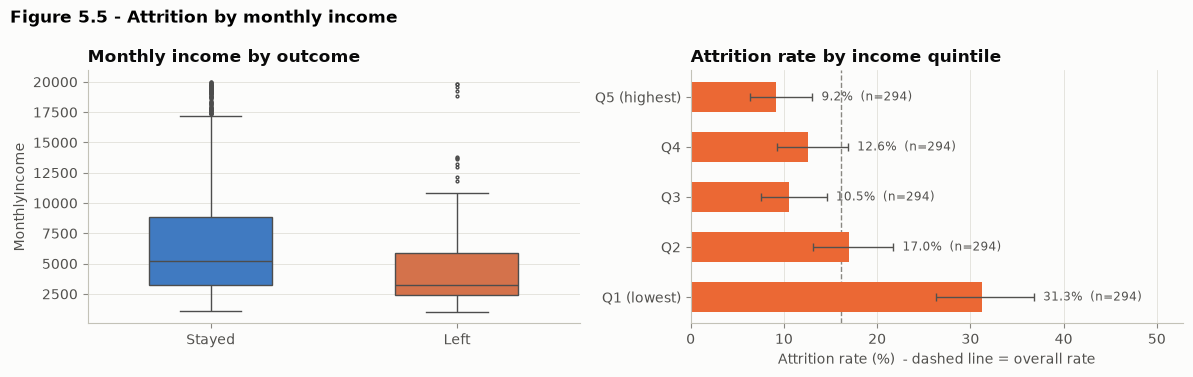

Outcome
Left      3202.0
Stayed    5204.0


In [24]:
eda["IncomeQuintile"] = pd.qcut(eda["MonthlyIncome"], q=5,
                                labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
print(eda.groupby("IncomeQuintile", observed=True)["MonthlyIncome"].agg(["min", "max"]).to_string())
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.boxplot(data=eda, x="Outcome", y="MonthlyIncome", order=["Stayed", "Left"], hue="Outcome",
            palette=OUTCOME_PALETTE, width=0.5, fliersize=2, ax=axes[0], legend=False)
axes[0].set_title("Monthly income by outcome", loc="left")
axes[0].set_xlabel("")
plot_attrition_rate(axes[1], eda, "IncomeQuintile", "Attrition rate by income quintile")
fig.suptitle("Figure 5.5 - Attrition by monthly income", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig_5_5_income")
plt.show()
print(eda.groupby("Outcome")["MonthlyIncome"].median().rename("Median monthly income").to_string())

**Observation.** Leavers earn less: their median monthly income is **3,202** against **5,204** for stayers. By income quintile, attrition is **31.3%** in the lowest fifth (≤ 2,695), 17.0% in the second, and only 9–13% in the top three. The relationship is not linear. Risk drops steeply over the lower part of the pay range and then flattens. Income is almost perfectly correlated with job level (r = 0.95), so these data cannot separate the effect of *pay* from the effect of *seniority*.

### 5.6 Attrition by overtime, 5.7 job satisfaction, and 5.8 work-life balance

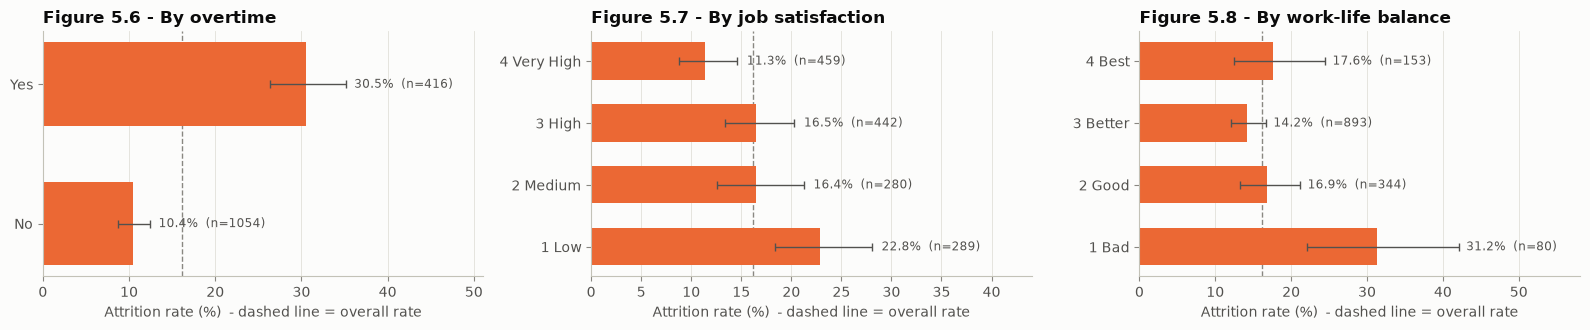

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
plot_attrition_rate(axes[0], eda, "OverTime", "Figure 5.6 - By overtime")
plot_attrition_rate(axes[1], eda, "JobSatisfaction", "Figure 5.7 - By job satisfaction",
                    labels=LEVEL_LABELS["JobSatisfaction"])
plot_attrition_rate(axes[2], eda, "WorkLifeBalance", "Figure 5.8 - By work-life balance",
                    labels=LEVEL_LABELS["WorkLifeBalance"])
fig.tight_layout()
save_fig(fig, "fig_5_6_5_8_overtime_satisfaction_wlb")
plt.show()

**Observation.**
- **Overtime** shows the largest single contrast among binary attributes: **30.5%** attrition with overtime (n = 416) vs **10.4%** without (n = 1,054), roughly three times higher.
- **Job satisfaction:** attrition is **22.8%** at "Low" and **11.3%** at "Very High". The middle levels are both about 16.5%.
- **Work-life balance** is *not* monotonic. Only the small "Bad" group stands out (**31.2%**, n = 80, wide interval). The other levels are 14–18%.
- Overtime may stand in for workload, role or team effects, so it is a strong *predictor* but not proven to be a *cause*.

### 5.9 Attrition by years at the company and 5.10 by years since last promotion

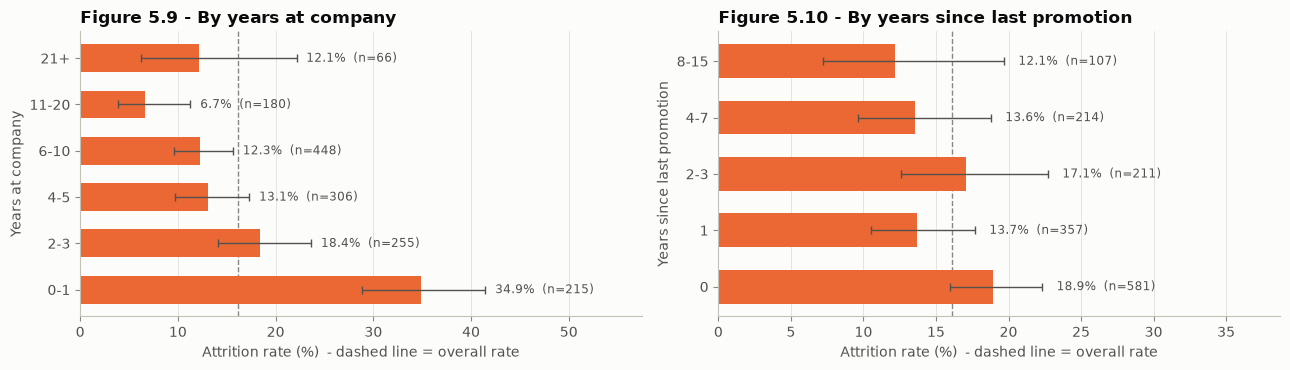

In [26]:
eda["TenureBand"] = pd.cut(eda["YearsAtCompany"], bins=[-1, 1, 3, 5, 10, 20, 40],
                           labels=["0-1", "2-3", "4-5", "6-10", "11-20", "21+"])
eda["PromotionBand"] = pd.cut(eda["YearsSinceLastPromotion"], bins=[-1, 0, 1, 3, 7, 15],
                              labels=["0", "1", "2-3", "4-7", "8-15"])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
plot_attrition_rate(axes[0], eda, "TenureBand", "Figure 5.9 - By years at company")
axes[0].set_ylabel("Years at company")
plot_attrition_rate(axes[1], eda, "PromotionBand", "Figure 5.10 - By years since last promotion")
axes[1].set_ylabel("Years since last promotion")
fig.tight_layout()
save_fig(fig, "fig_5_9_5_10_tenure_promotion")
plt.show()

**Observation.**
- **Tenure:** attrition is highest in the first two years at the company (**34.9%** for 0–1 years, n = 215) and falls to 6.7% for 11–20 years. Early-tenure departures dominate.
- **Years since last promotion** shows **no clear one-variable pattern** (12–19% in every band, r = −0.03). This variable is tied to tenure: new joiners have "0 years since promotion" by construction. Section 11 shows that once tenure is accounted for, the model gives it a positive association with risk. A relationship can look absent on its own and still appear when other variables are held constant.

### 5.11 Correlation heatmap (numeric variables)

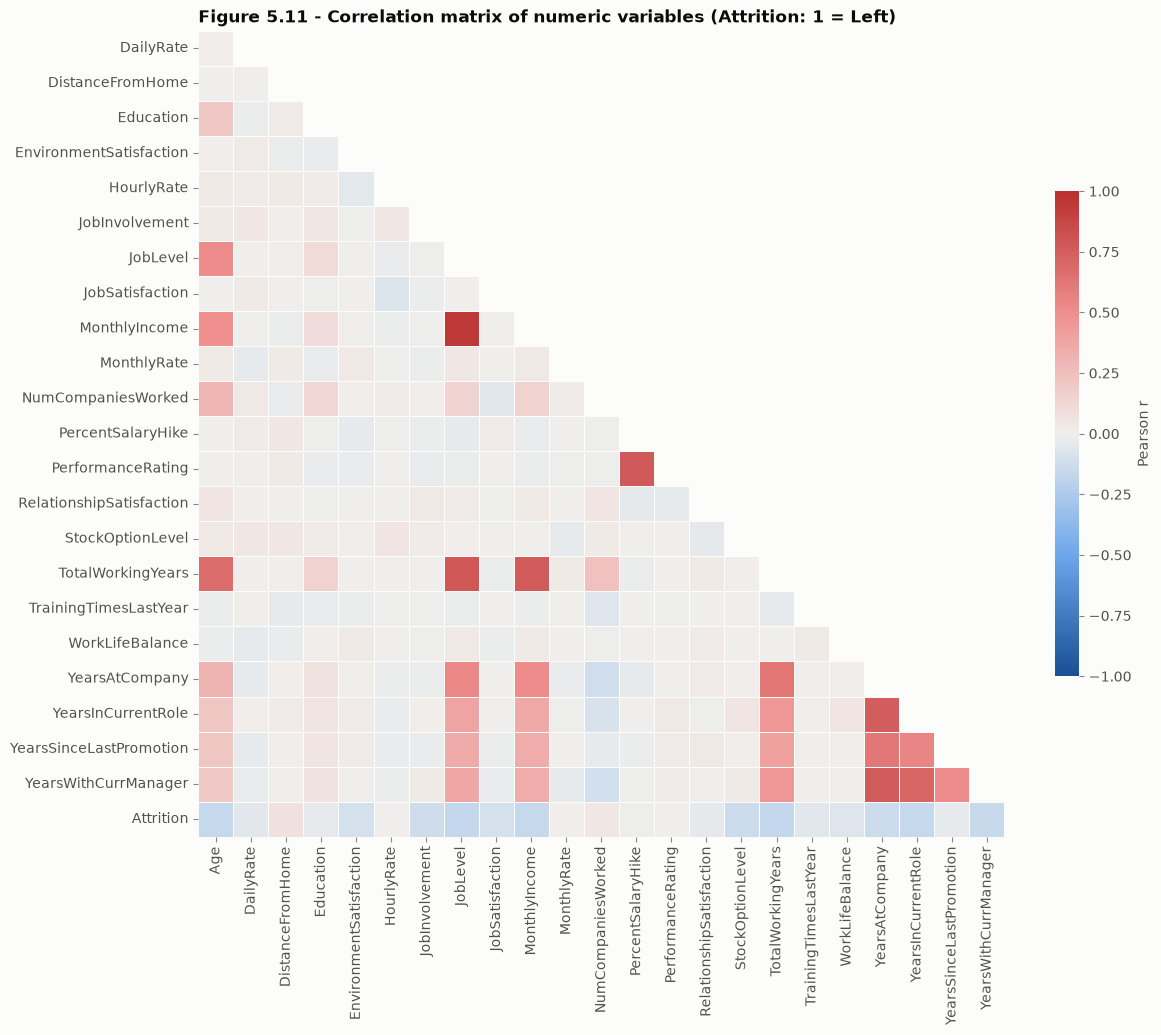

Strongly correlated feature pairs (|r| >= 0.7):


,Variable A,Variable B,r
177,JobLevel,MonthlyIncome,0.950
184,JobLevel,TotalWorkingYears,0.782
301,PercentSalaryHike,PerformanceRating,0.774
232,MonthlyIncome,TotalWorkingYears,0.773
478,YearsAtCompany,YearsWithCurrManager,0.769
476,YearsAtCompany,YearsInCurrentRole,0.759
502,YearsInCurrentRole,YearsWithCurrManager,0.714


Correlation of each numeric variable with Attrition (point-biserial r):
TotalWorkingYears          -0.171
JobLevel                   -0.169
YearsInCurrentRole         -0.161
MonthlyIncome              -0.160
Age                        -0.159
YearsWithCurrManager       -0.156
StockOptionLevel           -0.137
YearsAtCompany             -0.134
JobInvolvement             -0.130
JobSatisfaction            -0.103
EnvironmentSatisfaction    -0.103
WorkLifeBalance            -0.064
TrainingTimesLastYear      -0.059
DailyRate                  -0.057
RelationshipSatisfaction   -0.046
YearsSinceLastPromotion    -0.033
Education                  -0.031
PercentSalaryHike          -0.013
HourlyRate                 -0.007
PerformanceRating           0.003
MonthlyRate                 0.015
NumCompaniesWorked          0.043
DistanceFromHome            0.078


In [27]:
corr_cols = [c for c in df_clean.columns if pd.api.types.is_numeric_dtype(df_clean[c]) and c != TARGET] + [TARGET]
corr = df_clean[corr_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))  # hide upper triangle and the always-1 diagonal
fig, ax = plt.subplots(figsize=(13, 10.5))
sns.heatmap(corr.iloc[1:, :-1], mask=mask[1:, :-1], cmap=DIVERGING_CMAP, vmin=-1, vmax=1, center=0, square=True,
            linewidths=0.5, linecolor=SURFACE, cbar_kws={"shrink": 0.6, "label": "Pearson r"}, ax=ax)
ax.set_title("Figure 5.11 - Correlation matrix of numeric variables (Attrition: 1 = Left)", loc="left")
ax.grid(False)
save_fig(fig, "fig_5_11_correlation")
plt.show()

pairs = (corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1)).stack()
         .rename("r").reset_index().rename(columns={"level_0": "Variable A", "level_1": "Variable B"}))
pairs = pairs[(pairs["Variable A"] != TARGET) & (pairs["Variable B"] != TARGET)]
strong_pairs = pairs.loc[pairs["r"].abs() >= 0.7].sort_values("r", ascending=False).round(3)
print("Strongly correlated feature pairs (|r| >= 0.7):")
display(strong_pairs)
target_corr = corr[TARGET].drop(TARGET).sort_values()
print("Correlation of each numeric variable with Attrition (point-biserial r):")
print(target_corr.round(3).to_string())

**Observation.**
- **Strongly correlated feature groups:** JobLevel–MonthlyIncome (**r = 0.95**), JobLevel–TotalWorkingYears (0.78), PercentSalaryHike–PerformanceRating (0.77), MonthlyIncome–TotalWorkingYears (0.77), and the tenure variables YearsAtCompany / YearsInCurrentRole / YearsWithCurrManager (0.71–0.77). These groups will share importance in Stage 11.
- **Every numeric correlation with Attrition is weak** (|r| ≤ 0.17). The strongest are TotalWorkingYears (−0.171), JobLevel (−0.169), YearsInCurrentRole (−0.161), MonthlyIncome (−0.160) and Age (−0.159).
- Pearson r only captures *linear* relationships between *numeric* columns. Text columns such as OverTime, which shows the largest EDA contrast, are not in this matrix.
- No single variable separates leavers from stayers, which is why a multivariable model is needed.

### 5.12 Additional views supported by the dataset

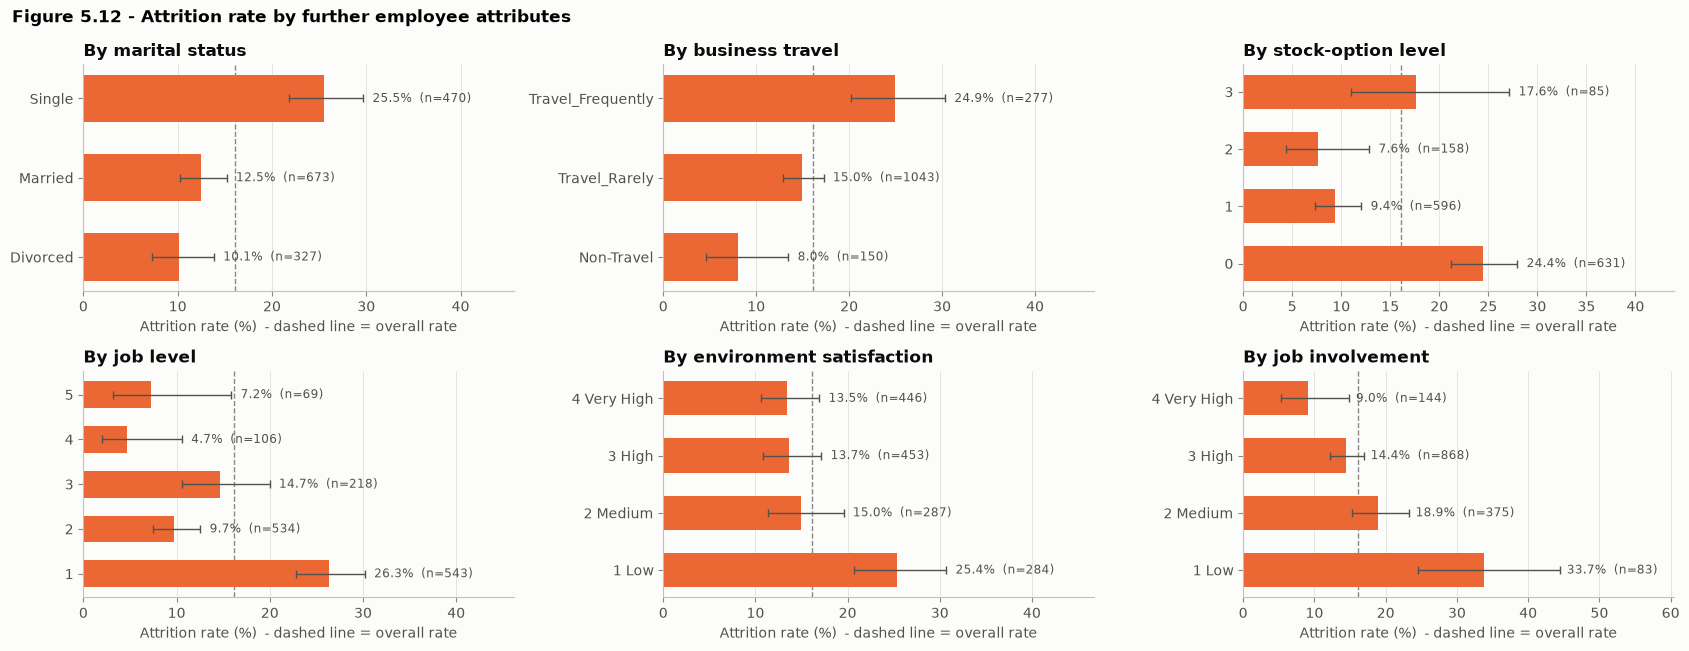

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(17, 6.6))
plot_attrition_rate(axes[0, 0], eda, "MaritalStatus", "By marital status", sort=True)
plot_attrition_rate(axes[0, 1], eda, "BusinessTravel", "By business travel",
                    order=["Non-Travel", "Travel_Rarely", "Travel_Frequently"])
plot_attrition_rate(axes[0, 2], eda, "StockOptionLevel", "By stock-option level")
plot_attrition_rate(axes[1, 0], eda, "JobLevel", "By job level")
plot_attrition_rate(axes[1, 1], eda, "EnvironmentSatisfaction", "By environment satisfaction",
                    labels=LEVEL_LABELS["EnvironmentSatisfaction"])
plot_attrition_rate(axes[1, 2], eda, "JobInvolvement", "By job involvement", labels=LEVEL_LABELS["JobInvolvement"])
fig.suptitle("Figure 5.12 - Attrition rate by further employee attributes", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig_5_12_additional")
plt.show()

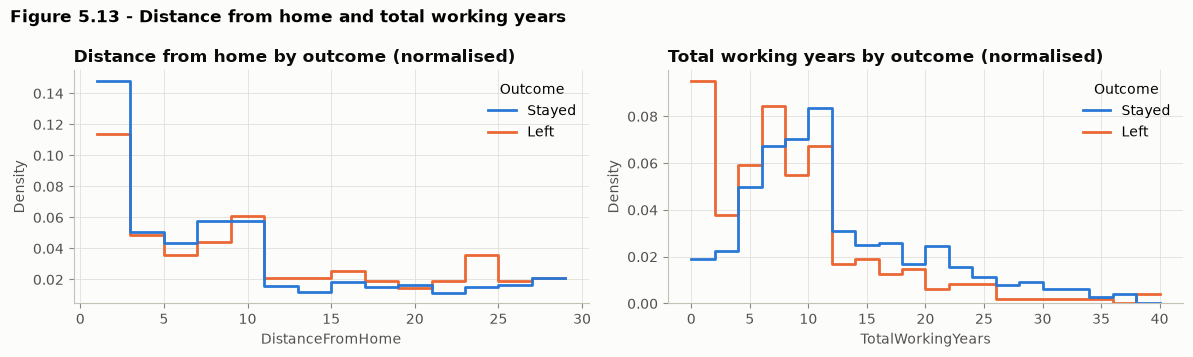

,Attribute,Highest-rate group,Highest rate,Lowest-rate group,Lowest rate,Spread
8,JobRole,Sales Representative,39.8%,Research Director,2.5%,37.3%
6,TenureBand,0-1,34.9%,11-20,6.7%,28.2%
5,AgeGroup,18-25,35.8%,36-45,9.2%,26.6%
13,JobInvolvement,1,33.7%,4,9.0%,24.7%
7,IncomeQuintile,Q1 (lowest),31.3%,Q5 (highest),9.2%,22.1%
3,JobLevel,1,26.3%,4,4.7%,21.6%
0,OverTime,Yes,30.5%,No,10.4%,20.1%
12,WorkLifeBalance,1,31.2%,3,14.2%,17.0%
2,BusinessTravel,Travel_Frequently,24.9%,Non-Travel,8.0%,16.9%
4,StockOptionLevel,0,24.4%,2,7.6%,16.8%


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
sns.histplot(data=eda, x="DistanceFromHome", hue="Outcome", hue_order=["Stayed", "Left"],
             palette=OUTCOME_PALETTE, bins=range(1, 31, 2), stat="density", common_norm=False,
             element="step", fill=False, linewidth=2, ax=axes[0])
axes[0].set_title("Distance from home by outcome (normalised)", loc="left")
sns.histplot(data=eda, x="TotalWorkingYears", hue="Outcome", hue_order=["Stayed", "Left"],
             palette=OUTCOME_PALETTE, bins=range(0, 42, 2), stat="density", common_norm=False,
             element="step", fill=False, linewidth=2, ax=axes[1])
axes[1].set_title("Total working years by outcome (normalised)", loc="left")
fig.suptitle("Figure 5.13 - Distance from home and total working years", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig_5_13_distance_experience")
plt.show()

# Summary table of the largest group differences found in EDA
eda_summary = []
for col in ["OverTime", "MaritalStatus", "BusinessTravel", "JobLevel", "StockOptionLevel", "AgeGroup",
            "TenureBand", "IncomeQuintile", "JobRole", "Department", "JobSatisfaction",
            "EnvironmentSatisfaction", "WorkLifeBalance", "JobInvolvement"]:
    t = attrition_rate_table(eda, col)
    eda_summary.append((col, t["rate"].idxmax(), t["rate"].max(), t["rate"].idxmin(), t["rate"].min()))
eda_summary = (pd.DataFrame(eda_summary, columns=["Attribute", "Highest-rate group", "Highest rate",
                                                  "Lowest-rate group", "Lowest rate"])
               .assign(Spread=lambda d: d["Highest rate"] - d["Lowest rate"])
               .sort_values("Spread", ascending=False))
eda_summary.to_csv(RESULTS_DIR / "eda_attrition_rate_summary.csv", index=False)
eda_summary.style.format({"Highest rate": "{:.1%}", "Lowest rate": "{:.1%}", "Spread": "{:.1%}"})

**Observation.**
- **Marital status:** Single **25.5%** vs Married 12.5% and Divorced 10.1%.
- **Business travel:** Travel_Frequently **24.9%** vs Non-Travel **8.0%**.
- **Stock options:** level 0 has **24.4%** attrition vs 7.6–9.4% at levels 1–2. Level 3 (17.6%, n = 85) is uncertain.
- **Job level:** level 1 has **26.3%** vs 4.7% at level 4.
- **Environment satisfaction:** "Low" is **25.4%**, the other levels 13–15%.
- **Job involvement:** "Low" is **33.7%** (n = 83) vs 9.0% at "Very High".
- Leavers live slightly further away (median distance 9 vs 7) and have less total experience (median 7 vs 10 years).

The summary table ranks attributes by the gap between their highest- and lowest-rate groups: **job role (37 percentage points)**, **tenure band (28)**, **age group (27)**, **job involvement (25)**, **income quintile (22)**, **job level (22)** and **overtime (20)**.

**Overall EDA picture.** In this dataset, attrition is concentrated among early-career, lower-level, lower-paid employees, those who work overtime or travel frequently, single employees, and those reporting low satisfaction or involvement. Many of these attributes overlap with one another. These are associations in fictional data and do not identify causes.

## 6. Feature Engineering and Feature Selection

**Inputs and target.** `X` holds the 30 remaining attributes and `y` holds `Attrition` (1 = Left).

**Selection decisions (target-independent).**
- *Removed:* the three constant columns (`EmployeeCount`, `Over18`, `StandardHours`) and the identifier `EmployeeNumber` (Stage 4).
- *Kept:* every other attribute, including weakly associated ones such as `DailyRate`, `HourlyRate` and `MonthlyRate`. Dropping features because of their relationship with the target on the full dataset would leak test information into the design. Regularised Logistic Regression and the tree ensembles can down-weight unhelpful inputs on their own.
- *Correlated features* (for example `JobLevel`, `MonthlyIncome` and `TotalWorkingYears`) are kept. They do not harm the predictions of these models, but they *do* complicate interpretation, because importance is shared between correlated features (Stage 11).

**Engineered candidate features.** Five domain-motivated features are built only from existing columns:

| Feature | Formula | Idea |
|---|---|---|
| `TenureRatio` | YearsAtCompany / TotalWorkingYears (0 if no experience) | share of career spent at this company |
| `AvgYearsPerCompany` | TotalWorkingYears / (NumCompaniesWorked + 1) | job-hopping tendency |
| `PromotionGapRatio` | YearsSinceLastPromotion / (YearsAtCompany + 1) | stagnation relative to tenure |
| `MeanSatisfaction` | mean of Environment, Job, Relationship satisfaction and Work-life balance | overall survey sentiment |
| `IncomePerJobLevel` | MonthlyIncome / JobLevel | pay relative to seniority |

The transformation is **stateless** (it learns nothing from data), so applying it inside the pipeline cannot leak information. We **do not assume** these features help. Section 9.1 measures their effect using cross-validation on the training data only and keeps them only if they improve performance.

**Feature importance ≠ causal importance.** A feature is *predictively* important if the model relies on it to separate leavers from stayers. That does not mean changing the feature would change the outcome. For example, `OverTime` may be predictive because overtime reflects workload, team or role, all of which also relate to leaving.

In [30]:
X = df_clean.drop(columns=[TARGET])
y = df_clean[TARGET]
categorical_features = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
numeric_features = [c for c in X.columns if c not in categorical_features]
print(f"X shape: {X.shape},  y shape: {y.shape}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")
print(f"Numeric features ({len(numeric_features)}), of which ordinal-coded: "
      f"{[c for c in numeric_features if c in ORDINAL_COLS]}")

# The feature-engineering function is defined in src/attrition_features.py (imported in Section 0)
# so that the saved model can be re-loaded outside this notebook. Its source code:
import inspect
print(inspect.getsource(add_engineered_features))
add_engineered_features(X)[ENGINEERED_FEATURES].describe().T.round(3)

X shape: (1470, 30),  y shape: (1470,)
Categorical features (7): ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
Numeric features (23), of which ordinal-coded: ['Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'WorkLifeBalance']
def add_engineered_features(frame):
    """Return a copy of `frame` with five ratio/aggregate features (stateless, no fitting)."""
    out = frame.copy()
    total_years = out["TotalWorkingYears"].replace(0, np.nan)
    out["TenureRatio"] = (out["YearsAtCompany"] / total_years).fillna(0.0)
    out["AvgYearsPerCompany"] = out["TotalWorkingYears"] / (out["NumCompaniesWorked"] + 1)
    out["PromotionGapRatio"] = out["YearsSinceLastPromotion"] / (out["YearsAtCompany"] + 1)
    out["MeanSatisfaction"] = out[["EnvironmentSatisfaction", "JobSatisfaction",
                                   "RelationshipSatisf

,count,mean,std,min,25%,50%,75%,max
TenureRatio,1470.0,0.678,0.328,0.0,0.412,0.800,1.000,1.000
AvgYearsPerCompany,1470.0,4.193,4.036,0.0,1.600,3.000,5.000,38.000
PromotionGapRatio,1470.0,0.236,0.269,0.0,0.000,0.143,0.429,0.917
MeanSatisfaction,1470.0,2.731,0.506,1.0,2.500,2.750,3.000,4.000
IncomePerJobLevel,1470.0,2973.801,770.641,1009.0,2394.125,2856.500,3478.833,4999.000


**Leakage check by prediction time.** The intended use is to score *current* employees. Every retained feature (demographics, role, pay, tenure, survey ratings) would be in an HR system before an employee resigns, so none of them is a post-exit record. The remaining risk is the snapshot-timing issue described in Section 3.2.

## 7. Encoding and Scaling

**Categorical features → One-Hot Encoding.** Models need numbers. One-hot encoding creates one 0/1 column per category, which avoids implying a false order (for example, that *Sales* > *R&D*). `handle_unknown="ignore"` means a category never seen in training is encoded as all zeros instead of crashing the model.

**Ordinal survey scales** (1–4 ratings, `Education`, `JobLevel`, `StockOptionLevel`) are kept as integers because their order is meaningful.

**Scaling.** `StandardScaler` transforms each numeric feature to mean 0 and standard deviation 1. This matters for **Logistic Regression**: the L2 penalty treats all coefficients equally, so features must be on comparable scales, and the solver converges faster. **Tree-based models** (Random Forest, XGBoost) split on thresholds of one feature at a time, and any monotonic rescaling leaves the ordering of values (and therefore the possible splits) unchanged. They therefore receive unscaled numbers.

**Imputation.** The data has no missing values, but median/most-frequent imputers are included so that the pipeline does not fail on an incomplete record at prediction time.

**Leakage prevention.** Everything is wrapped in `Pipeline` + `ColumnTransformer`. When a pipeline is fitted, imputers, encoders and scalers learn their statistics (medians, means, categories) from the data passed to `fit` only, which is the training set or the training folds in cross-validation.

In [31]:
def build_preprocessor(scale_numeric):
    """ColumnTransformer: numeric -> impute (+ optional scaling); categorical -> impute + one-hot."""
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scale", StandardScaler()))
    categorical_steps = [("impute", SimpleImputer(strategy="most_frequent")),
                         ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]
    return ColumnTransformer(
        [("num", Pipeline(numeric_steps), make_column_selector(dtype_include="number")),
         ("cat", Pipeline(categorical_steps), make_column_selector(dtype_exclude="number"))],
        verbose_feature_names_out=False)


def build_pipeline(model, scale_numeric, engineered):
    """Full modelling pipeline: [optional feature engineering] -> preprocessing -> classifier."""
    steps = []
    if engineered:
        steps.append(("engineer", FunctionTransformer(add_engineered_features)))
    steps += [("preprocess", build_preprocessor(scale_numeric)), ("model", model)]
    return Pipeline(steps)


build_preprocessor(scale_numeric=True)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The

## 8. Train-Test Split

The data is split **80% training / 20% testing** with **stratification** on `Attrition` and a fixed seed (`random_state=42`).

- **Why stratify?** Only about 16% of employees left. A purely random split could, by chance, put noticeably more or fewer leavers in the test set, which would distort the metrics. Stratified sampling keeps the class proportions almost identical in both sets.
- **Test-set discipline.** The test set is used **once**, in Stage 10, to evaluate the already-tuned models. All tuning, feature-set decisions and threshold choices use **5-fold stratified cross-validation on the training set only**.
- 1,470 rows is small but enough for an 80/20 split (294 test rows, 47 leavers). Because the test set is small, Stage 10 also reports bootstrap confidence intervals.

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

split_summary = pd.DataFrame({
    "Rows": [len(X), len(X_train), len(X_test)],
    "Leavers": [int(y.sum()), int(y_train.sum()), int(y_test.sum())],
    "Attrition rate": [y.mean(), y_train.mean(), y_test.mean()],
}, index=["Full data", "Training (80%)", "Testing (20%)"])
display(split_summary.style.format({"Attrition rate": "{:.2%}"}))

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Demonstrate that preprocessing is fitted on training data only
demo_preprocessor = build_preprocessor(scale_numeric=True).fit(X_train)
X_train_transformed = demo_preprocessor.transform(X_train)
print(f"Transformed training matrix: {X_train_transformed.shape} "
      f"(30 raw columns -> {X_train_transformed.shape[1]} after one-hot encoding)")
print("Scaler means are learned from the 1,176 training rows only, e.g. Age mean =",
      round(demo_preprocessor.named_transformers_["num"].named_steps["scale"].mean_[0], 3))

,Rows,Leavers,Attrition rate
Full data,1470,237,16.12%
Training (80%),1176,190,16.16%
Testing (20%),294,47,15.99%


Transformed training matrix: (1176, 51) (30 raw columns -> 51 after one-hot encoding)
Scaler means are learned from the 1,176 training rows only, e.g. Age mean = 36.998


## 9. Model Development

**Class imbalance strategy.** With roughly 5 stayers per leaver, an unweighted model tends to predict "Stayed" for almost everyone. Because the business objective is to *find* at-risk employees, each model is given **class weights** that make the two classes contribute equally to the training loss: `class_weight="balanced"` (Logistic Regression), `"balanced_subsample"` (Random Forest), and `scale_pos_weight = #stayers / #leavers` computed on the training set (XGBoost). Weighting changes how the model trades precision for recall. It does not create new information.

**Tuning protocol.** Every model is tuned with 5-fold stratified cross-validation on the **training set**, using **ROC-AUC** as the selection score. ROC-AUC measures ranking quality independently of the decision threshold. Precision, recall, F1 and PR-AUC (average precision) are recorded for the chosen settings.

### 9.0 Reference baseline
A `DummyClassifier` that always predicts the majority class shows the lowest acceptable bar and why accuracy alone is misleading.

In [33]:
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "accuracy": "accuracy",
           "precision": make_scorer(precision_score, zero_division=0), "recall": "recall", "f1": "f1"}
cv_summary = {}


def summarise_cv(name, cv_scores):
    """Store mean and std of each cross-validated metric (keys like 'test_roc_auc' or 'mean_test_roc_auc')."""
    cv_summary[name] = {metric: (np.mean(cv_scores[metric]), np.std(cv_scores[metric])) for metric in SCORING}


dummy = build_pipeline(DummyClassifier(strategy="most_frequent"), scale_numeric=False, engineered=False)
dummy_cv = cross_validate(dummy, X_train, y_train, cv=CV, scoring=SCORING, error_score="raise")
summarise_cv("Majority-class baseline", {m: dummy_cv[f"test_{m}"] for m in SCORING})
print({m: round(np.mean(dummy_cv[f"test_{m}"]), 3) for m in SCORING})

{'roc_auc': np.float64(0.5), 'pr_auc': np.float64(0.162), 'accuracy': np.float64(0.838), 'precision': np.float64(0.0), 'recall': np.float64(0.0), 'f1': np.float64(0.0)}


### 9.1 Does feature engineering help? (measured, training data only)

Each model is cross-validated with sensible default settings on the original features and on the original + engineered features. The engineered features are adopted only if they raise the mean CV ROC-AUC averaged over the three models.

In [34]:
neg, pos = np.bincount(y_train)
SCALE_POS_WEIGHT = neg / pos
print(f"Training set: {neg} stayed, {pos} left -> scale_pos_weight = {SCALE_POS_WEIGHT:.3f}")


def make_logistic():
    return LogisticRegression(class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE)


def make_random_forest():
    return RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                  random_state=RANDOM_STATE, n_jobs=1)


def make_xgboost():
    return XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, objective="binary:logistic",
                         eval_metric="logloss", tree_method="hist", importance_type="gain",
                         scale_pos_weight=SCALE_POS_WEIGHT, random_state=RANDOM_STATE, n_jobs=1)


MODEL_FACTORIES = {"Logistic Regression": (make_logistic, True),
                   "Random Forest": (make_random_forest, False),
                   "XGBoost": (make_xgboost, False)}

fe_rows = []
for name, (factory, scale) in MODEL_FACTORIES.items():
    for engineered in (False, True):
        scores = cross_validate(build_pipeline(factory(), scale, engineered), X_train, y_train,
                                cv=CV, scoring="roc_auc", n_jobs=-1)["test_score"]
        fe_rows.append((name, "original + engineered" if engineered else "original", scores.mean(), scores.std()))
fe_results = pd.DataFrame(fe_rows, columns=["Model", "Feature set", "CV ROC-AUC mean", "CV ROC-AUC std"])
fe_pivot = fe_results.pivot(index="Model", columns="Feature set", values="CV ROC-AUC mean")
fe_pivot["Change"] = fe_pivot["original + engineered"] - fe_pivot["original"]
display(fe_pivot.round(4))

USE_ENGINEERED = bool(fe_pivot["Change"].mean() > 0)
print(f"Average change in CV ROC-AUC: {fe_pivot['Change'].mean():+.4f}")
print(f"Decision: {'USE' if USE_ENGINEERED else 'DO NOT USE'} the engineered features in the final models.")

Training set: 986 stayed, 190 left -> scale_pos_weight = 5.189


Feature set,original,original + engineered,Change
Model,,,
Logistic Regression,0.8273,0.8304,0.0031
Random Forest,0.8076,0.8184,0.0108
XGBoost,0.7977,0.8004,0.0027


Average change in CV ROC-AUC: +0.0056
Decision: USE the engineered features in the final models.


**Interpretation – feature engineering.**
- Adding the five engineered features raised the mean CV ROC-AUC for all three models: Logistic Regression **+0.0031**, Random Forest **+0.0108**, XGBoost **+0.0027** (average **+0.0056**). Under the pre-stated rule they are therefore **adopted**.
- The gains are **much smaller than the fold-to-fold standard deviation of ROC-AUC (≈ 0.02–0.035)**. The direction is consistent, but the evidence for a real improvement is weak, and the features should be seen as a minor refinement rather than a significant gain.
- Because they are adopted, the saved model depends on `src/attrition_features.py`.

### 9.2 Model 1 – Logistic Regression (baseline)

Logistic Regression models the log-odds of leaving as a linear combination of the features, $\log\frac{p}{1-p} = \beta_0 + \beta_1x_1 + \dots + \beta_kx_k$, and turns it into a probability with the sigmoid function $p = 1/(1+e^{-z})$. It is fast and well understood. Because it is linear on standardised features, its coefficients are directly interpretable, which makes it the natural **baseline**. `C` is the inverse of the L2 regularisation strength (smaller `C` = stronger shrinkage of the coefficients) and is tuned by grid search. `max_iter=5000` ensures the solver converges.

In [35]:
search_settings = dict(cv=CV, scoring=SCORING, refit="roc_auc", n_jobs=-1, return_train_score=True)

lr_search = GridSearchCV(
    build_pipeline(make_logistic(), scale_numeric=True, engineered=USE_ENGINEERED),
    param_grid={"model__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]},
    **search_settings)
lr_search.fit(X_train, y_train)


def report_search(name, search):
    best = search.best_index_
    results = search.cv_results_
    summarise_cv(name, {m: [results[f"split{k}_test_{m}"][best] for k in range(CV.n_splits)] for m in SCORING})
    print(f"{name}: best params = {search.best_params_}")
    print(f"  CV ROC-AUC = {results['mean_test_roc_auc'][best]:.4f} +/- {results['std_test_roc_auc'][best]:.4f}"
          f"   (train-fold ROC-AUC = {results['mean_train_roc_auc'][best]:.4f})")


report_search("Logistic Regression", lr_search)

Logistic Regression: best params = {'model__C': 0.1}
  CV ROC-AUC = 0.8334 +/- 0.0277   (train-fold ROC-AUC = 0.8817)


### 9.3 Model 2 – Random Forest

A **decision tree** splits the data with a sequence of yes/no questions (for example *OverTime = Yes?*, *MonthlyIncome < 2,500?*) and chooses each question to make the resulting groups as pure as possible (Gini impurity). A single deep tree memorises its training data (high variance). A **Random Forest** (Breiman, 2001) is an *ensemble* of many trees. Each tree is trained on a bootstrap sample of the rows and considers only a random subset of features at each split, and the forest averages the trees' votes. Averaging many decorrelated trees lowers the variance. The grid tunes tree depth, minimum leaf size and the number of features tried per split, which together control overfitting.

In [36]:
rf_search = GridSearchCV(
    build_pipeline(make_random_forest(), scale_numeric=False, engineered=USE_ENGINEERED),
    param_grid={"model__max_depth": [4, 8, 12, None],
                "model__min_samples_leaf": [1, 3, 5, 10],
                "model__max_features": ["sqrt", 0.3]},
    **search_settings)
rf_search.fit(X_train, y_train)
report_search("Random Forest", rf_search)

Random Forest: best params = {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1}
  CV ROC-AUC = 0.8184 +/- 0.0355   (train-fold ROC-AUC = 1.0000)


### 9.4 Model 3 – XGBoost

**Gradient boosting** builds trees *sequentially*. Each new, small tree is fitted to correct the errors (the gradient of the loss) of the ensemble so far, and its contribution is shrunk by a *learning rate*. **XGBoost** (Chen and Guestrin, 2016) is an optimised implementation of this idea that adds L1/L2 regularisation of the leaf weights, row and column subsampling, and efficient histogram-based split finding. Boosting can fit complex patterns but overfits if trees are too deep or too many, so the search below covers depth, learning rate, number of trees, subsampling and regularisation. A *randomised* search (40 sampled combinations) is used because the full grid would be very large. The search's own `random_state` keeps it reproducible.

In [37]:
xgb_search = RandomizedSearchCV(
    build_pipeline(make_xgboost(), scale_numeric=False, engineered=USE_ENGINEERED),
    param_distributions={"model__n_estimators": [100, 200, 300, 500, 800],
                         "model__learning_rate": [0.01, 0.02, 0.05, 0.1, 0.2],
                         "model__max_depth": [2, 3, 4, 5, 6],
                         "model__min_child_weight": [1, 3, 5, 10],
                         "model__subsample": [0.6, 0.8, 1.0],
                         "model__colsample_bytree": [0.4, 0.6, 0.8, 1.0],
                         "model__reg_lambda": [0.5, 1, 5, 10],
                         "model__gamma": [0, 0.5, 1]},
    n_iter=40, random_state=RANDOM_STATE, **search_settings)
xgb_search.fit(X_train, y_train)
report_search("XGBoost", xgb_search)

XGBoost: best params = {'model__subsample': 0.6, 'model__reg_lambda': 1, 'model__n_estimators': 200, 'model__min_child_weight': 10, 'model__max_depth': 2, 'model__learning_rate': 0.1, 'model__gamma': 1, 'model__colsample_bytree': 0.4}
  CV ROC-AUC = 0.8291 +/- 0.0201   (train-fold ROC-AUC = 0.9735)


In [38]:
best_models = {"Logistic Regression": lr_search.best_estimator_,
               "Random Forest": rf_search.best_estimator_,
               "XGBoost": xgb_search.best_estimator_}

hyperparameters = pd.DataFrame([
    {"Model": name, "Tuned hyperparameters": search.best_params_}
    for name, search in [("Logistic Regression", lr_search), ("Random Forest", rf_search), ("XGBoost", xgb_search)]
])
hyperparameters["Tuned hyperparameters"] = hyperparameters["Tuned hyperparameters"].apply(
    lambda p: ", ".join(f"{k.replace('model__', '')}={v}" for k, v in p.items()))
hyperparameters.to_csv(RESULTS_DIR / "tuned_hyperparameters.csv", index=False)
with pd.option_context("display.max_colwidth", 200):
    display(hyperparameters)

cv_table = pd.DataFrame({name: {m: f"{mean:.3f} ± {std:.3f}" for m, (mean, std) in scores.items()}
                         for name, scores in cv_summary.items()}).T
cv_table.columns = ["ROC-AUC", "PR-AUC", "Accuracy", "Precision", "Recall", "F1"]
cv_table.to_csv(RESULTS_DIR / "cv_results_training.csv")
print("5-fold cross-validation on the TRAINING set (mean ± std), threshold 0.5:")
display(cv_table)

,Model,Tuned hyperparameters
0,Logistic Regression,C=0.1
1,Random Forest,"max_depth=None, max_features=sqrt, min_samples_leaf=1"
2,XGBoost,"subsample=0.6, reg_lambda=1, n_estimators=200, min_child_weight=10, max_depth=2, learning_rate=0.1, gamma=1, colsample_bytree=0.4"


5-fold cross-validation on the TRAINING set (mean ± std), threshold 0.5:


,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
Majority-class baseline,0.500 ± 0.000,0.162 ± 0.000,0.838 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
Logistic Regression,0.833 ± 0.028,0.625 ± 0.071,0.760 ± 0.040,0.383 ± 0.049,0.737 ± 0.055,0.501 ± 0.040
Random Forest,0.818 ± 0.035,0.576 ± 0.058,0.860 ± 0.008,0.861 ± 0.134,0.168 ± 0.068,0.272 ± 0.090
XGBoost,0.829 ± 0.020,0.618 ± 0.051,0.833 ± 0.013,0.492 ± 0.029,0.679 ± 0.051,0.568 ± 0.014


**Interpretation – cross-validation (training data).**
- **Logistic Regression** (C = 0.1, i.e. fairly strong L2 regularisation): CV ROC-AUC **0.833 ± 0.028**, training-fold ROC-AUC 0.882. This small gap means mild overfitting.
- **Random Forest** (fully grown trees, `max_features="sqrt"`): CV ROC-AUC **0.818 ± 0.035**, but training-fold ROC-AUC **1.000**. The individual trees memorise the training data, and averaging only partly makes up for it.
- **XGBoost:** the search chose a heavily regularised configuration (depth-2 trees, 200 rounds, learning rate 0.1, 60% row / 40% column subsampling, `min_child_weight = 10`, `gamma = 1`). It reaches CV ROC-AUC **0.829 ± 0.020** with training-fold ROC-AUC 0.974.
- **At the default 0.5 threshold:**
  - Logistic Regression has the highest recall (**0.737**, precision 0.383).
  - XGBoost has the best F1 (**0.568**).
  - Random Forest almost never predicts "Left" (recall **0.168**). Its fully grown trees have pure leaves, so class weights barely move the averaged votes above 0.5. RF *ranks* employees reasonably well (ROC-AUC 0.818), but 0.5 is the wrong threshold for it.
- **Accuracy is misleading here.** Random Forest has the *highest* accuracy (0.860) and the *lowest* F1.
- All three models are far better than the majority-class baseline (ROC-AUC 0.5, recall 0).

## 10. Model Evaluation (held-out test set)

The three tuned pipelines were refitted on the full training set and are now evaluated **once** on the untouched test set (294 employees).

| Metric | Formula | Question it answers |
|---|---|---|
| Accuracy | (TP + TN) / (TP + TN + FP + FN) | What share of all predictions is correct? |
| Precision | TP / (TP + FP) | Of employees flagged as at risk, what share actually left? |
| Recall (sensitivity) | TP / (TP + FN) | Of employees who actually left, what share did we flag? |
| F1-score | 2 · Precision · Recall / (Precision + Recall) | Balance of precision and recall (harmonic mean) |
| ROC-AUC | Area under the TPR-vs-FPR curve | Probability that a random leaver is ranked above a random stayer |
| PR-AUC (average precision) | Area under the precision–recall curve | Ranking quality focused on the minority class |

TP = leavers correctly flagged, FN = leavers missed, FP = stayers wrongly flagged, TN = stayers correctly cleared.

- **Accuracy can mislead.** The majority-class baseline is ≈ 84% accurate and finds no leavers at all.
- **Recall matters** because a missed leaver (FN) is a missed chance to have a retention conversation.
- **Precision matters** because each false alarm (FP) costs HR time and can feel intrusive to the employee. The right balance depends on the cost of each error, which is a business decision.

In [39]:
def evaluate(model, X_eval, y_eval, threshold=0.5):
    proba = model.predict_proba(X_eval)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {"Accuracy": accuracy_score(y_eval, pred),
            "Precision": precision_score(y_eval, pred, zero_division=0),
            "Recall": recall_score(y_eval, pred),
            "F1": f1_score(y_eval, pred),
            "ROC-AUC": roc_auc_score(y_eval, proba),
            "PR-AUC": average_precision_score(y_eval, proba)}, proba, pred


dummy.fit(X_train, y_train)
test_results, test_proba, test_pred = {}, {}, {}
for name, model in {"Majority-class baseline": dummy, **best_models}.items():
    test_results[name], test_proba[name], test_pred[name] = evaluate(model, X_test, y_test)

comparison = pd.DataFrame(test_results).T
comparison.to_csv(RESULTS_DIR / "model_comparison_test.csv")
print("Held-out TEST set performance (threshold = 0.5):")
display(comparison.style.format("{:.3f}").highlight_max(axis=0, subset=pd.IndexSlice[list(best_models), :],
                                                         props="font-weight:bold"))

Held-out TEST set performance (threshold = 0.5):


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Majority-class baseline,0.840,0.000,0.000,0.000,0.500,0.160
Logistic Regression,0.762,0.361,0.638,0.462,0.803,0.582
Random Forest,0.850,0.714,0.106,0.185,0.790,0.455
XGBoost,0.786,0.389,0.596,0.471,0.786,0.524


In [40]:
for name in best_models:
    print(f"=== {name} ===")
    print(classification_report(y_test, test_pred[name], target_names=["Stayed (0)", "Left (1)"], digits=3))

=== Logistic Regression ===
              precision    recall  f1-score   support

  Stayed (0)      0.919     0.785     0.847       247
    Left (1)      0.361     0.638     0.462        47

    accuracy                          0.762       294
   macro avg      0.640     0.712     0.654       294
weighted avg      0.830     0.762     0.786       294

=== Random Forest ===
              precision    recall  f1-score   support

  Stayed (0)      0.854     0.992     0.918       247
    Left (1)      0.714     0.106     0.185        47

    accuracy                          0.850       294
   macro avg      0.784     0.549     0.551       294
weighted avg      0.831     0.850     0.801       294

=== XGBoost ===
              precision    recall  f1-score   support

  Stayed (0)      0.914     0.822     0.866       247
    Left (1)      0.389     0.596     0.471        47

    accuracy                          0.786       294
   macro avg      0.652     0.709     0.668       294
weighted

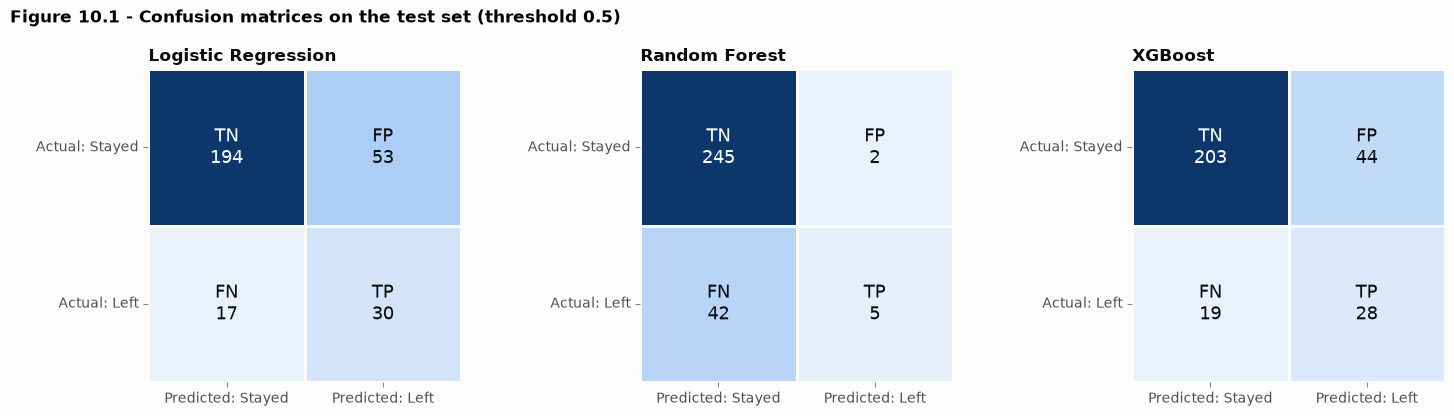

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, name in zip(axes, best_models):
    cm = confusion_matrix(y_test, test_pred[name])
    sns.heatmap(cm, annot=False, cmap=SEQUENTIAL_CMAP, cbar=False, linewidths=2, linecolor=SURFACE,
                square=True, ax=ax)
    labels = [["TN", "FP"], ["FN", "TP"]]
    for i in range(2):
        for j in range(2):
            ax.text(j + 0.5, i + 0.5, f"{labels[i][j]}\n{cm[i, j]}", ha="center", va="center", fontsize=13,
                    color="white" if cm[i, j] > cm.max() * 0.5 else INK)
    ax.set_xticklabels(["Predicted: Stayed", "Predicted: Left"])
    ax.set_yticklabels(["Actual: Stayed", "Actual: Left"], rotation=0)
    ax.set_title(name, loc="left")
    ax.grid(False)
fig.suptitle("Figure 10.1 - Confusion matrices on the test set (threshold 0.5)", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig_10_1_confusion_matrices")
plt.show()

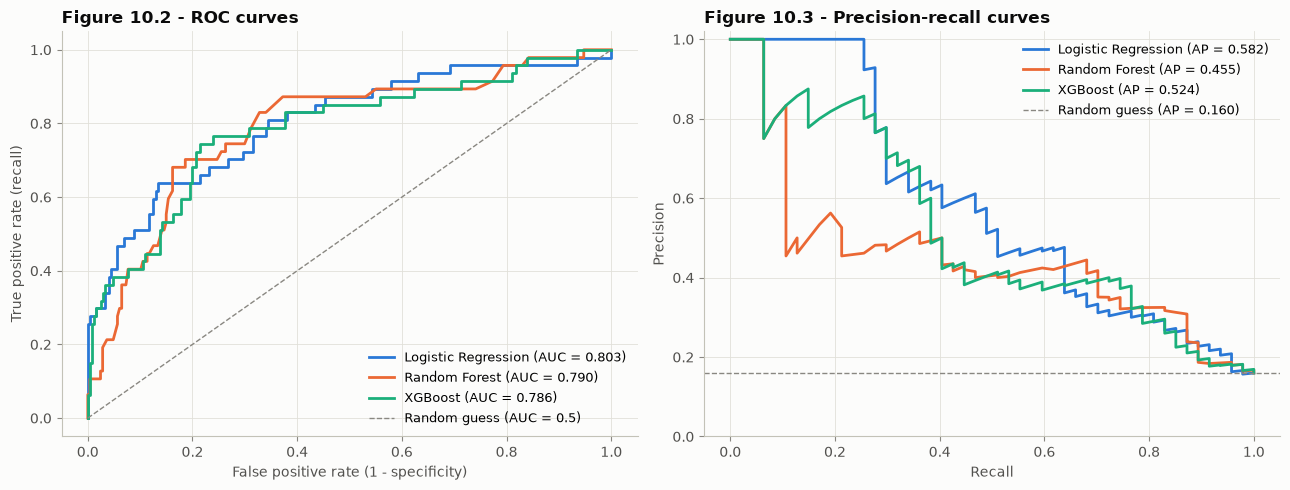

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in best_models:
    fpr, tpr, _ = roc_curve(y_test, test_proba[name])
    axes[0].plot(fpr, tpr, color=MODEL_COLORS[name], linewidth=2,
                 label=f"{name} (AUC = {test_results[name]['ROC-AUC']:.3f})")
    prec, rec, _ = precision_recall_curve(y_test, test_proba[name])
    axes[1].plot(rec, prec, color=MODEL_COLORS[name], linewidth=2,
                 label=f"{name} (AP = {test_results[name]['PR-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1, label="Random guess (AUC = 0.5)")
axes[0].set(xlabel="False positive rate (1 - specificity)", ylabel="True positive rate (recall)")
axes[0].set_title("Figure 10.2 - ROC curves", loc="left")
axes[1].axhline(y_test.mean(), color=MUTED, linestyle="--", linewidth=1,
                label=f"Random guess (AP = {y_test.mean():.3f})")
axes[1].set(xlabel="Recall", ylabel="Precision", ylim=(0, 1.02))
axes[1].set_title("Figure 10.3 - Precision-recall curves", loc="left")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "upper right", fontsize=9)
fig.tight_layout()
save_fig(fig, "fig_10_2_10_3_roc_pr_curves")
plt.show()

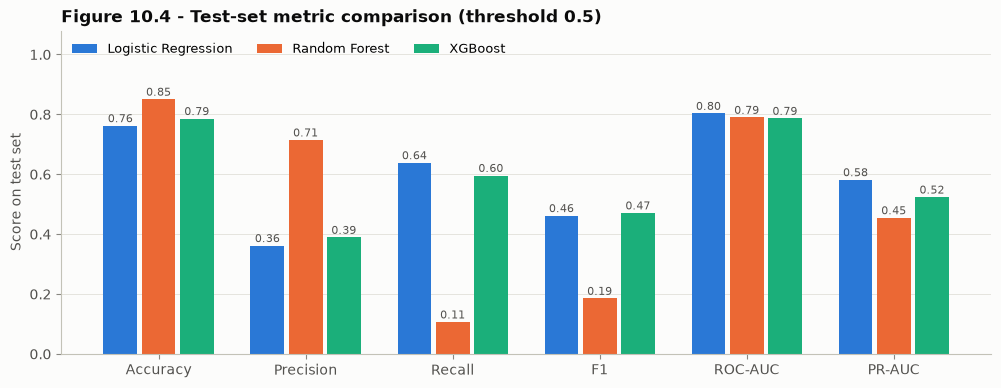

In [43]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
fig, ax = plt.subplots(figsize=(12, 4.2))
width = 0.26
x_pos = np.arange(len(metrics_to_plot))
for i, name in enumerate(best_models):
    values = comparison.loc[name, metrics_to_plot].values
    bars = ax.bar(x_pos + (i - 1) * width, values, width=width - 0.03, color=MODEL_COLORS[name], label=name, zorder=2)
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.012, f"{value:.2f}", ha="center", fontsize=8, color=INK_2)
ax.set_xticks(x_pos, metrics_to_plot)
ax.set_ylim(0, 1.08)
ax.set_ylabel("Score on test set")
ax.set_title("Figure 10.4 - Test-set metric comparison (threshold 0.5)", loc="left")
ax.legend(ncol=3, loc="upper left", fontsize=9)
ax.grid(axis="x", visible=False)
save_fig(fig, "fig_10_4_metric_comparison")
plt.show()

### 10.1 How reliable are these test scores? (bootstrap confidence intervals)

With only about 47 leavers in the test set, a few predictions changing would move recall by several percentage points. The test set is resampled with replacement 1,000 times, and each metric is recomputed on each resample to get 95% intervals.

In [44]:
rng = np.random.default_rng(RANDOM_STATE)
n_boot = 1000
y_test_arr = y_test.to_numpy()
boot = {name: {"ROC-AUC": [], "Recall": [], "Precision": [], "F1": []} for name in best_models}
for _ in range(n_boot):
    idx = rng.integers(0, len(y_test_arr), len(y_test_arr))
    if y_test_arr[idx].min() == y_test_arr[idx].max():
        continue
    for name in best_models:
        yt, pp, pr = y_test_arr[idx], test_proba[name][idx], test_pred[name][idx]
        boot[name]["ROC-AUC"].append(roc_auc_score(yt, pp))
        boot[name]["Recall"].append(recall_score(yt, pr))
        boot[name]["Precision"].append(precision_score(yt, pr, zero_division=0))
        boot[name]["F1"].append(f1_score(yt, pr))
ci_table = pd.DataFrame({name: {m: f"{test_results[name][m]:.3f} [{np.percentile(v, 2.5):.3f}, {np.percentile(v, 97.5):.3f}]"
                                for m, v in scores.items()} for name, scores in boot.items()}).T
ci_table.to_csv(RESULTS_DIR / "test_bootstrap_ci.csv")
print("Test-set point estimate [95% bootstrap interval]:")
display(ci_table)

Test-set point estimate [95% bootstrap interval]:


,ROC-AUC,Recall,Precision,F1
Logistic Regression,"0.803 [0.724, 0.880]","0.638 [0.500, 0.773]","0.361 [0.258, 0.463]","0.462 [0.352, 0.555]"
Random Forest,"0.790 [0.709, 0.859]","0.106 [0.022, 0.204]","0.714 [0.285, 1.000]","0.185 [0.043, 0.327]"
XGBoost,"0.786 [0.702, 0.865]","0.596 [0.452, 0.736]","0.389 [0.278, 0.500]","0.471 [0.356, 0.576]"


**Interpretation – held-out test set (294 employees, 47 leavers, threshold 0.5).**

| Model | ROC-AUC | PR-AUC | Recall | Precision | F1 | Accuracy | TP / FN / FP / TN |
|---|---|---|---|---|---|---|---|
| Logistic Regression | **0.803** | **0.582** | **0.638** | 0.361 | 0.462 | 0.762 | 30 / 17 / 53 / 194 |
| Random Forest | 0.790 | 0.455 | 0.106 | **0.714** | 0.185 | **0.850** | 5 / 42 / 2 / 245 |
| XGBoost | 0.786 | 0.524 | 0.596 | 0.389 | **0.471** | 0.786 | 28 / 19 / 44 / 203 |

- **Accuracy trap.** Random Forest has the best accuracy (85.0%) but finds only **5 of 47** leavers. That accuracy is barely above the 84.0% obtained by predicting "Stayed" for everyone in this test set.
- **Ranking quality.** Logistic Regression has the highest ROC-AUC and PR-AUC. Its precision–recall curve shows that the employees it scores highest are mostly true leavers.
- **Uncertainty.** The bootstrap intervals for ROC-AUC overlap heavily (LR 0.724–0.880, RF 0.709–0.859, XGB 0.702–0.865), and recall intervals are about ±0.14 wide. **This test set cannot reliably separate the three models' ranking ability.** Claims such as "model A is better than model B" should be read with that caveat.
- Test ROC-AUCs (0.79–0.80) are slightly below the CV estimates (0.82–0.83) but fall within the CV spread and the bootstrap intervals, so there is no sign of a problem with the split.

### 10.2 Final model selection

**Rule, fixed before looking at the test set:** choose the model with the highest **cross-validated ROC-AUC on the training data**. ROC-AUC is used because the purpose is to *rank* employees by risk, and recall at a chosen operating threshold can then be tuned to HR capacity. If two models are within one cross-validation standard deviation of each other, prefer the simpler, more interpretable one. The test set then serves as an independent confirmation and is not used to make the choice.

In [45]:
cv_auc = pd.DataFrame({name: {"CV ROC-AUC mean": cv_summary[name]["roc_auc"][0],
                              "CV ROC-AUC std": cv_summary[name]["roc_auc"][1],
                              "Test ROC-AUC": test_results[name]["ROC-AUC"],
                              "Test recall": test_results[name]["Recall"],
                              "Test precision": test_results[name]["Precision"]}
                       for name in best_models}).T
display(cv_auc.round(4))

complexity_order = ["Logistic Regression", "Random Forest", "XGBoost"]  # simplest first
best_cv_name = cv_auc["CV ROC-AUC mean"].idxmax()
best_cv, best_std = cv_auc.loc[best_cv_name, ["CV ROC-AUC mean", "CV ROC-AUC std"]]
within_one_std = [n for n in complexity_order if cv_auc.loc[n, "CV ROC-AUC mean"] >= best_cv - best_std]
FINAL_MODEL_NAME = within_one_std[0]
final_model = best_models[FINAL_MODEL_NAME]
print(f"Highest CV ROC-AUC: {best_cv_name} ({best_cv:.4f} +/- {best_std:.4f})")
print(f"Models within one std of the best: {within_one_std}")
print(f"==> Selected final model: {FINAL_MODEL_NAME}")

,CV ROC-AUC mean,CV ROC-AUC std,Test ROC-AUC,Test recall,Test precision
Logistic Regression,0.8334,0.0277,0.8030,0.6383,0.3614
Random Forest,0.8184,0.0355,0.7897,0.1064,0.7143
XGBoost,0.8291,0.0201,0.7864,0.5957,0.3889


Highest CV ROC-AUC: Logistic Regression (0.8334 +/- 0.0277)
Models within one std of the best: ['Logistic Regression', 'Random Forest', 'XGBoost']
==> Selected final model: Logistic Regression


### 10.3 Choosing an operating threshold for the final model

The default threshold of 0.5 is arbitrary. Out-of-fold probabilities for the **training** set are produced with `cross_val_predict` (each training row is predicted by a model that did not see it), and every threshold from 0.05 to 0.95 is scored on them. The test set is not used.

**Rule.** Section 10 stated that missing a leaver (FN) is costlier than a false alarm (FP), because the intended action is a low-cost supportive conversation. The threshold is therefore chosen to maximise the **F2-score**, which weights recall twice as heavily as precision:

$$F_\beta = \frac{(1+\beta^2)\cdot \text{Precision}\cdot\text{Recall}}{\beta^2\cdot\text{Precision} + \text{Recall}}, \qquad \beta = 2$$

For transparency the F1-optimal threshold (equal weighting) and the default 0.5 are also evaluated on the test set. An HR team with different costs or capacity would pick a different point on the same curve.

F2-optimal threshold (selected): 0.40   |   F1-optimal threshold: 0.70


,precision,recall,f1,f2
threshold (training out-of-fold),,,,
0.4,0.324,0.816,0.463,0.626
0.5,0.376,0.737,0.498,0.618
0.7,0.636,0.553,0.592,0.568


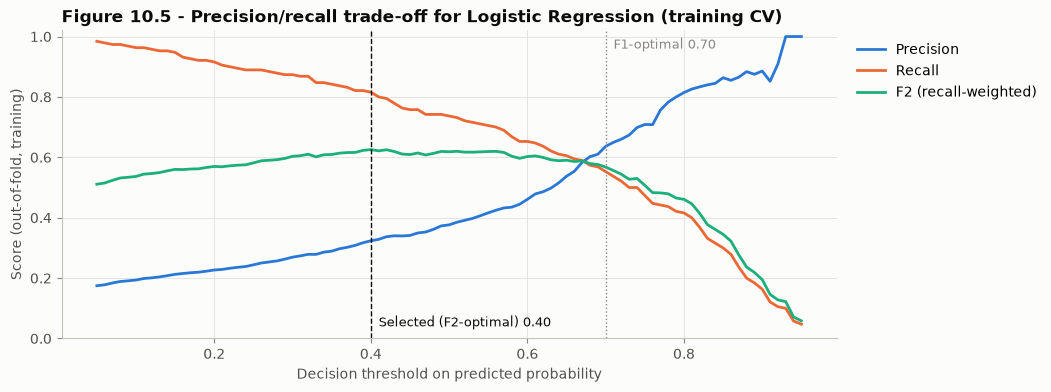

Logistic Regression on the TEST set at each candidate threshold:


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Threshold,,,,,,
0.50 (default),0.762,0.361,0.638,0.462,0.803,0.582
0.70 (F1-optimal),0.861,0.575,0.489,0.529,0.803,0.582
"0.40 (F2-optimal, selected)",0.694,0.313,0.766,0.444,0.803,0.582


Confusion matrix at the selected threshold 0.40: TN=168, FP=79, FN=11, TP=36


In [46]:
oof_proba = cross_val_predict(clone(final_model), X_train, y_train, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2)
threshold_curve = pd.DataFrame({
    "threshold": thresholds,
    "precision": [precision_score(y_train, oof_proba >= t, zero_division=0) for t in thresholds],
    "recall": [recall_score(y_train, oof_proba >= t) for t in thresholds],
    "f1": [f1_score(y_train, oof_proba >= t) for t in thresholds],
    "f2": [fbeta_score(y_train, oof_proba >= t, beta=2) for t in thresholds],
})
F1_THRESHOLD = float(threshold_curve.loc[threshold_curve["f1"].idxmax(), "threshold"])
FINAL_THRESHOLD = float(threshold_curve.loc[threshold_curve["f2"].idxmax(), "threshold"])
print(f"F2-optimal threshold (selected): {FINAL_THRESHOLD:.2f}   |   F1-optimal threshold: {F1_THRESHOLD:.2f}")
display(threshold_curve.set_index("threshold").loc[sorted({0.5, F1_THRESHOLD, FINAL_THRESHOLD})].round(3)
        .rename_axis("threshold (training out-of-fold)"))

fig, ax = plt.subplots(figsize=(10, 4))
for metric, color, label in [("precision", "#2a78d6", "Precision"), ("recall", "#eb6834", "Recall"),
                             ("f2", "#1baf7a", "F2 (recall-weighted)")]:
    ax.plot(threshold_curve["threshold"], threshold_curve[metric], color=color, linewidth=2, label=label)
ax.axvline(F1_THRESHOLD, color=MUTED, linestyle=":", linewidth=1)
ax.text(F1_THRESHOLD + 0.01, 0.96, f"F1-optimal {F1_THRESHOLD:.2f}", fontsize=9, color=MUTED)
ax.axvline(FINAL_THRESHOLD, color=INK, linestyle="--", linewidth=1)
ax.text(FINAL_THRESHOLD + 0.01, 0.04, f"Selected (F2-optimal) {FINAL_THRESHOLD:.2f}", fontsize=9, color=INK)
ax.set(xlabel="Decision threshold on predicted probability", ylabel="Score (out-of-fold, training)", ylim=(0, 1.02))
ax.set_title(f"Figure 10.5 - Precision/recall trade-off for {FINAL_MODEL_NAME} (training CV)", loc="left")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
save_fig(fig, "fig_10_5_threshold_tradeoff")
plt.show()

FINAL_LABEL = f"{FINAL_THRESHOLD:.2f} (F2-optimal, selected)"
threshold_comparison = pd.DataFrame({
    "0.50 (default)": evaluate(final_model, X_test, y_test, 0.5)[0],
    f"{F1_THRESHOLD:.2f} (F1-optimal)": evaluate(final_model, X_test, y_test, F1_THRESHOLD)[0],
    FINAL_LABEL: evaluate(final_model, X_test, y_test, FINAL_THRESHOLD)[0],
}).T.rename_axis("Threshold")
threshold_comparison.to_csv(RESULTS_DIR / "final_model_threshold_comparison.csv")
print(f"{FINAL_MODEL_NAME} on the TEST set at each candidate threshold:")
display(threshold_comparison.round(3))
cm_final = confusion_matrix(y_test, (test_proba[FINAL_MODEL_NAME] >= FINAL_THRESHOLD).astype(int))
print(f"Confusion matrix at the selected threshold {FINAL_THRESHOLD:.2f}: TN={cm_final[0,0]}, FP={cm_final[0,1]}, "
      f"FN={cm_final[1,0]}, TP={cm_final[1,1]}")

**Interpretation – final model and threshold.**
- **Choice of model.** Logistic Regression has the highest CV ROC-AUC (0.833 ± 0.028). XGBoost (0.829) and Random Forest (0.818) are both within one standard deviation of it, so the pre-stated rule selects the simplest model: **Logistic Regression**. The test set agrees, though not decisively: LR has the highest test ROC-AUC (0.803) and PR-AUC (0.582). XGBoost's slightly higher test F1 at 0.5 (0.471 vs 0.462) is within noise and depends on the threshold.
- **Practical advantages of LR.** Its coefficients can be explained to HR, the saved model is only a few kilobytes, and its probabilities change smoothly with the inputs.
- **Threshold.** On training out-of-fold predictions, the F2-optimal threshold is **0.40** (OOF recall 0.816, precision 0.324) and the F1-optimal threshold is 0.70 (recall 0.553, precision 0.636).
- **Test results at the selected threshold 0.40:**
  - **recall 0.766**: 36 of 47 leavers flagged;
  - **precision 0.313**: 115 employees flagged in total, 79 of them false alarms;
  - accuracy 0.694, F1 0.444.
- **The trade-off in plain words:** to find about three-quarters of leavers, roughly two out of every three flagged employees will turn out not to leave. This is acceptable only when the follow-up is cheap and supportive (for example a check-in conversation), never when it is punitive. A team with less capacity could use 0.70 instead (test recall 0.489, precision 0.575).

## 11. Feature Importance and Model Interpretation

Four complementary views are used:
1. **Logistic Regression coefficients.** These are on standardised features. A positive coefficient raises the predicted odds of leaving, and `exp(coef)` is the odds multiplier for a one-standard-deviation increase (or for having the category, in the case of one-hot columns).
2. **Random Forest impurity importance.** This is the average decrease in Gini impurity contributed by each feature. It is known to be biased towards continuous and high-cardinality features (Strobl et al., 2007).
3. **XGBoost gain importance.** This is the average improvement in the loss when a feature is used for a split.
4. **Permutation importance** (model-agnostic, on the **test set**). It measures how much the test ROC-AUC drops when one *original* column is randomly shuffled. Because it works on the raw columns, all one-hot dummies of `JobRole` (for example) are shuffled together.

Feature names after preprocessing are read from the fitted `ColumnTransformer` (`get_feature_names_out`), so names always line up with the model's inputs.

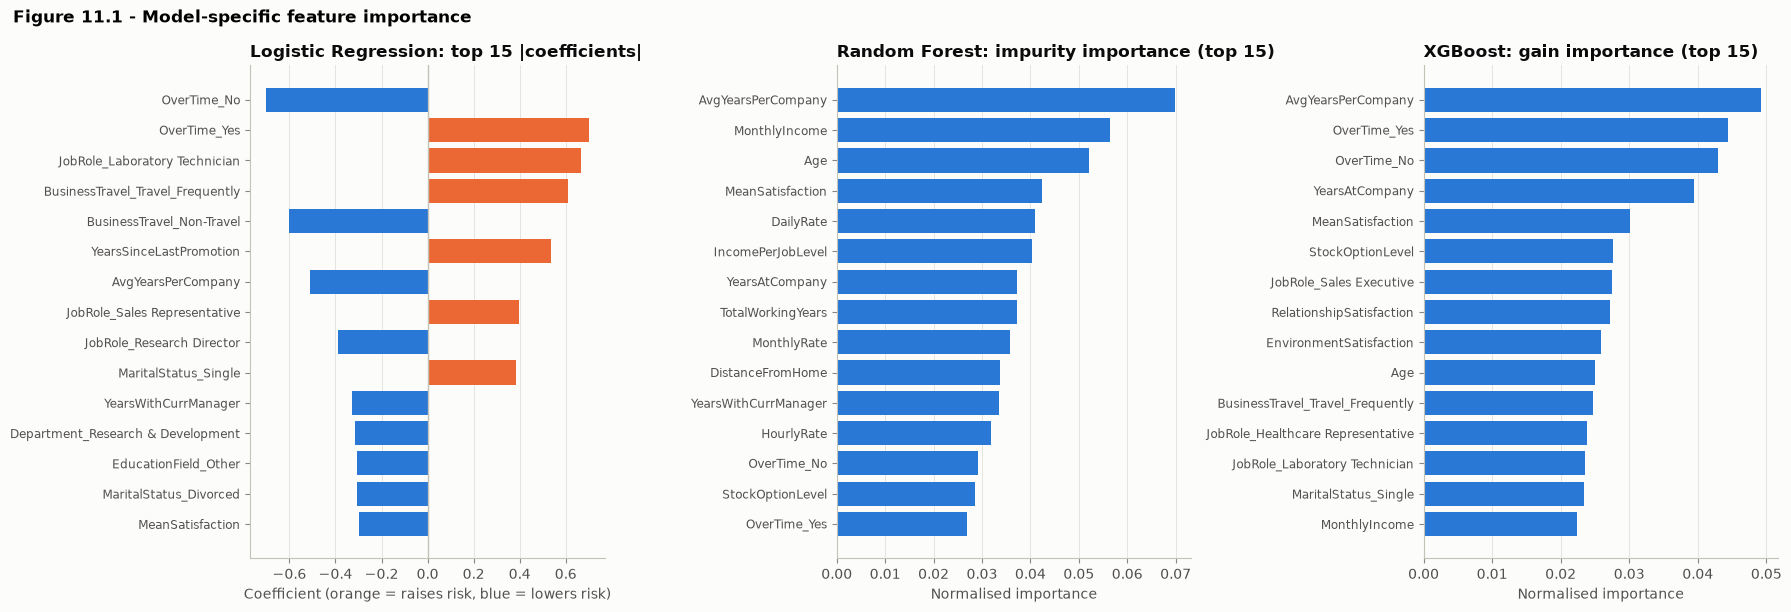

Logistic Regression - 10 largest coefficients with odds ratios:


,feature,coefficient,odds_ratio
0,OverTime_No,-0.701,0.496
1,OverTime_Yes,0.699,2.011
2,JobRole_Laboratory Technician,0.665,1.944
3,BusinessTravel_Travel_Frequently,0.609,1.839
4,BusinessTravel_Non-Travel,-0.602,0.548
5,YearsSinceLastPromotion,0.534,1.706
6,AvgYearsPerCompany,-0.509,0.601
7,JobRole_Sales Representative,0.396,1.486
8,JobRole_Research Director,-0.388,0.678
9,MaritalStatus_Single,0.386,1.471


In [47]:
def transformed_feature_names(pipeline):
    return pipeline.named_steps["preprocess"].get_feature_names_out()


lr_model = best_models["Logistic Regression"]
lr_coef = pd.DataFrame({"feature": transformed_feature_names(lr_model),
                        "coefficient": lr_model.named_steps["model"].coef_[0]})
lr_coef["odds_ratio"] = np.exp(lr_coef["coefficient"])
lr_coef = lr_coef.reindex(lr_coef["coefficient"].abs().sort_values(ascending=False).index)

rf_importance = pd.Series(best_models["Random Forest"].named_steps["model"].feature_importances_,
                          index=transformed_feature_names(best_models["Random Forest"])).sort_values(ascending=False)
xgb_importance = pd.Series(best_models["XGBoost"].named_steps["model"].feature_importances_,
                           index=transformed_feature_names(best_models["XGBoost"])).sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 6.2))
top_lr = lr_coef.head(15).iloc[::-1]
axes[0].barh(top_lr["feature"], top_lr["coefficient"],
             color=[LEFT_COLOR if c > 0 else STAYED_COLOR for c in top_lr["coefficient"]], zorder=2)
axes[0].axvline(0, color=AXIS, linewidth=1)
axes[0].set_title("Logistic Regression: top 15 |coefficients|", loc="left")
axes[0].set_xlabel("Coefficient (orange = raises risk, blue = lowers risk)")
for ax, series, title in [(axes[1], rf_importance, "Random Forest: impurity importance (top 15)"),
                          (axes[2], xgb_importance, "XGBoost: gain importance (top 15)")]:
    top = series.head(15).iloc[::-1]
    ax.barh(top.index, top.values, color="#2a78d6", zorder=2)
    ax.set_title(title, loc="left")
    ax.set_xlabel("Normalised importance")
for ax in axes:
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8.5)
fig.suptitle("Figure 11.1 - Model-specific feature importance", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig_11_1_model_specific_importance")
plt.show()

print("Logistic Regression - 10 largest coefficients with odds ratios:")
display(lr_coef.head(10).round(3).reset_index(drop=True))

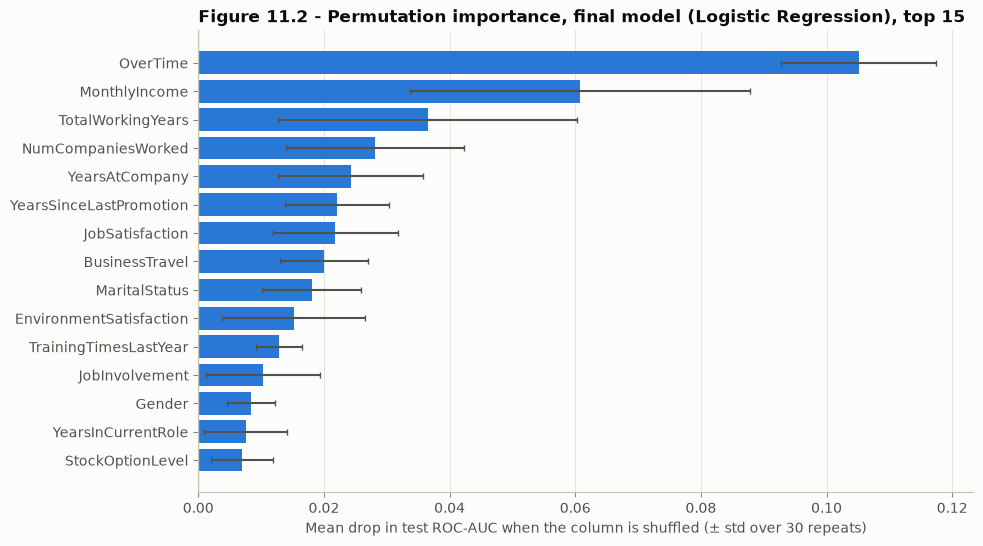

Permutation-importance rank of each original column for each model (1 = most important), top 12:


,Logistic Regression,Random Forest,XGBoost,Mean rank
OverTime,1,1,1,1.000000
JobSatisfaction,7,2,5,4.666667
BusinessTravel,8,5,4,5.666667
StockOptionLevel,15,3,2,6.666667
MaritalStatus,9,4,8,7.000000
YearsSinceLastPromotion,6,7,13,8.666667
EnvironmentSatisfaction,10,6,12,9.333333
MonthlyIncome,2,28,3,11.000000
NumCompaniesWorked,4,26,6,12.000000
TrainingTimesLastYear,11,13,14,12.666667


In [48]:
perm_tables = {}
for name, model in best_models.items():
    result = permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=30,
                                    random_state=RANDOM_STATE, n_jobs=-1)
    perm_tables[name] = pd.DataFrame({"mean_drop_in_auc": result.importances_mean,
                                      "std": result.importances_std},
                                     index=X_test.columns).sort_values("mean_drop_in_auc", ascending=False)

final_perm = perm_tables[FINAL_MODEL_NAME]
top_perm = final_perm.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_perm.index, top_perm["mean_drop_in_auc"], xerr=top_perm["std"], color=MODEL_COLORS[FINAL_MODEL_NAME],
        ecolor=INK_2, capsize=2, zorder=2)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_xlabel("Mean drop in test ROC-AUC when the column is shuffled (± std over 30 repeats)")
ax.set_title(f"Figure 11.2 - Permutation importance, final model ({FINAL_MODEL_NAME}), top 15", loc="left")
ax.grid(axis="y", visible=False)
save_fig(fig, "fig_11_2_permutation_importance_final")
plt.show()

rank_table = pd.DataFrame({name: table["mean_drop_in_auc"].rank(ascending=False).astype(int)
                           for name, table in perm_tables.items()})
rank_table["Mean rank"] = rank_table.mean(axis=1)
rank_table = rank_table.sort_values("Mean rank")
rank_table.to_csv(RESULTS_DIR / "permutation_importance_ranks.csv")
final_perm.to_csv(RESULTS_DIR / "permutation_importance_final_model.csv")
print("Permutation-importance rank of each original column for each model (1 = most important), top 12:")
display(rank_table.head(12))

In [49]:
# Direction of effect for the most important original columns (observed rates, not causal effects)
top_columns = final_perm.head(8).index.tolist()
direction_rows = []
for col in top_columns:
    if pd.api.types.is_numeric_dtype(X[col]) and X[col].nunique() > 6:
        left, stayed = df_clean.loc[df_clean[TARGET] == 1, col], df_clean.loc[df_clean[TARGET] == 0, col]
        direction_rows.append((col, f"mean {left.mean():.2f} (left) vs {stayed.mean():.2f} (stayed); "
                                    f"median {left.median():g} vs {stayed.median():g}"))
    else:
        rates = attrition_rate_table(df_clean, col)["rate"]
        direction_rows.append((col, f"highest rate: {rates.idxmax()} ({rates.max():.1%}); "
                                    f"lowest: {rates.idxmin()} ({rates.min():.1%})"))
with pd.option_context("display.max_colwidth", 120):
    display(pd.DataFrame(direction_rows, columns=["Top permutation-importance column", "Observed pattern in the data"]))

,Top permutation-importance column,Observed pattern in the data
0,OverTime,highest rate: Yes (30.5%); lowest: No (10.4%)
1,MonthlyIncome,mean 4787.09 (left) vs 6832.74 (stayed); median 3202 vs 5204
2,TotalWorkingYears,mean 8.24 (left) vs 11.86 (stayed); median 7 vs 10
3,NumCompaniesWorked,mean 2.94 (left) vs 2.65 (stayed); median 1 vs 2
4,YearsAtCompany,mean 5.13 (left) vs 7.37 (stayed); median 3 vs 6
5,YearsSinceLastPromotion,mean 1.95 (left) vs 2.23 (stayed); median 1 vs 1
6,JobSatisfaction,highest rate: 1 (22.8%); lowest: 4 (11.3%)
7,BusinessTravel,highest rate: Travel_Frequently (24.9%); lowest: Non-Travel (8.0%)


**Interpretation – what the models rely on.**

**Permutation importance for the final Logistic Regression** (drop in test ROC-AUC when the column is shuffled):

| Rank | Column | Drop in ROC-AUC |
|---|---|---|
| 1 | **OverTime** | **0.105** (by far the largest) |
| 2 | MonthlyIncome | 0.061 |
| 3 | TotalWorkingYears | 0.036 |
| 4 | NumCompaniesWorked | 0.028 |
| 5 | YearsAtCompany | 0.024 |
| 6 | YearsSinceLastPromotion | 0.022 |
| 7 | JobSatisfaction | 0.022 |
| 8 | BusinessTravel | 0.020 |
| 9 | MaritalStatus | 0.018 |
| 10 | EnvironmentSatisfaction | 0.015 |

Beyond rank 1 the error bars are wide (for example ±0.027 for MonthlyIncome), so the exact order of ranks 2–10 is not reliable.

**Agreement across models.**
- **OverTime is ranked #1 by all three models.** JobSatisfaction, BusinessTravel, StockOptionLevel and MaritalStatus also rank highly for the tree models.
- MonthlyIncome is #2 for Logistic Regression and #3 for XGBoost but **#28 for Random Forest**. The most likely reason is that the forest can get the same information from correlated columns (JobLevel, TotalWorkingYears, IncomePerJobLevel), so shuffling income alone barely hurts it. This is the correlated-feature problem in practice.

**Logistic Regression coefficients (standardised inputs, other variables held constant).**
- **OverTime:** Yes = +0.70 and No = −0.70, so the Yes-vs-No contrast is 1.40. That corresponds to roughly **4× higher predicted odds** of leaving with overtime.
- **Job role and travel:** Laboratory Technician (+0.67), Travel_Frequently (+0.61) vs Non-Travel (−0.60), Sales Representative (+0.40) and Single (+0.39) raise the predicted risk. Research Director (−0.39) lowers it.
- **Years since last promotion (+0.53 per standard deviation).** It looked flat in the one-variable EDA. Once tenure and experience are held constant, a longer wait for promotion is associated with higher predicted risk.
- **AvgYearsPerCompany (−0.51):** a longer average stay per employer is associated with lower risk.

**Possible HR reading (hypotheses, not conclusions).** Workload and overtime, early-career pay and progression, frequent travel, and low job or environment satisfaction are the areas where this model finds the strongest signals. They are candidates for *group-level* review, such as overtime policy, onboarding in the first two years, and pay bands for entry-level roles. Each would need properly designed evaluation before anyone concludes that changing it reduces attrition.

**Fairness note.** The model also uses `Gender` (permutation rank 13, drop 0.008) and `MaritalStatus` (rank 9). Using such personal characteristics in employment decisions is legally and ethically sensitive. Any real use would need a fairness audit and a comparison with a model that excludes them; this is listed as future work.

**Limitations of feature-importance methods.**
- *Correlated features share or hide importance.* `JobLevel`, `MonthlyIncome` and `TotalWorkingYears` are strongly correlated. Shuffling one of them barely hurts the model when another carries the same information, so each can look less important than the information they share.
- *Impurity importance is biased* towards continuous features with many possible split points, and it is computed on training data.
- *Permutation importance on a small test set is noisy* (note the error bars), and shuffling can create unrealistic combinations (e.g. a job level of 1 with a very high income).
- *Prediction is not causation.* A high importance means the model uses the feature. It does not show that changing the feature would change whether someone leaves.

## 12. Final Prediction

`predict_attrition()` takes one employee's raw attributes (a dictionary with the same 30 columns used in training), validates them, runs them through the full fitted pipeline (engineering → imputation/encoding/scaling → model), and returns the predicted class, the estimated probability, and a plain-language message.

The output is a **model estimate based on patterns in a fictional dataset, not a certainty**. It must not be used to make hiring, firing, or other consequential decisions about an individual.

In [50]:
TRAINING_SCHEMA = {
    "columns": list(X_train.columns),
    "categorical_levels": {c: sorted(X_train[c].unique().tolist()) for c in categorical_features},
    "numeric_ranges": {c: (float(X_train[c].min()), float(X_train[c].max())) for c in numeric_features},
}


def predict_attrition(employee, model=final_model, threshold=FINAL_THRESHOLD, schema=TRAINING_SCHEMA):
    """Estimate attrition risk for one employee.

    Parameters
    ----------
    employee : dict  mapping each training column name to a value.
    model : fitted scikit-learn Pipeline.
    threshold : probability at or above which the employee is classified as 'likely to leave'.

    Returns
    -------
    dict with predicted_class (0/1), label, probability, warnings, and a readable message.
    """
    if not isinstance(employee, dict):
        raise TypeError("employee must be a dict of {column: value}.")
    missing_cols = [c for c in schema["columns"] if c not in employee]
    if missing_cols:
        raise ValueError(f"Missing required fields: {missing_cols}")
    unknown_cols = [c for c in employee if c not in schema["columns"]]
    warnings_found = [f"Ignored unknown field(s): {unknown_cols}"] if unknown_cols else []

    row = {}
    for col in schema["columns"]:
        value = employee[col]
        if col in schema["categorical_levels"]:
            if not isinstance(value, str):
                raise TypeError(f"{col} must be text, got {type(value).__name__}.")
            if value not in schema["categorical_levels"][col]:
                warnings_found.append(f"{col}='{value}' was not seen in training; it is encoded as 'unknown'.")
        else:
            try:
                value = float(value)
            except (TypeError, ValueError):
                raise TypeError(f"{col} must be numeric, got {value!r}.") from None
            if not np.isfinite(value):
                raise ValueError(f"{col} must be a finite number.")
            low, high = schema["numeric_ranges"][col]
            if not low <= value <= high:
                warnings_found.append(f"{col}={value:g} is outside the training range [{low:g}, {high:g}]; "
                                      "the estimate is less reliable.")
        row[col] = value

    frame = pd.DataFrame([row], columns=schema["columns"])
    for col in schema["categorical_levels"]:
        frame[col] = frame[col].astype(str)
    probability = float(model.predict_proba(frame)[0, 1])
    predicted_class = int(probability >= threshold)
    label = "Likely to leave" if predicted_class else "Likely to stay"
    message = (f"Estimated attrition probability: {probability:.1%} (decision threshold {threshold:.2f}) -> {label}. "
               "This is a statistical estimate from patterns in historical (fictional) data, not a certainty, "
               "and should only prompt supportive, group-level HR review - never an individual employment decision.")
    return {"predicted_class": predicted_class, "label": label, "probability": round(probability, 4),
            "threshold": threshold, "warnings": warnings_found, "message": message}

In [51]:
# Example 1 and 2: real employees from the TEST set (never seen during training or tuning)
test_leaver_idx = y_test[y_test == 1].index[0]
test_stayer_idx = y_test[y_test == 0].index[0]
for idx in (test_leaver_idx, test_stayer_idx):
    employee = X_test.loc[idx].to_dict()
    result = predict_attrition(employee)
    print(f"Test-set row {idx} (actual outcome: {'Left' if y_test[idx] == 1 else 'Stayed'})")
    print(f"  Key attributes: Age={employee['Age']}, JobRole={employee['JobRole']}, OverTime={employee['OverTime']}, "
          f"MonthlyIncome={employee['MonthlyIncome']}, YearsAtCompany={employee['YearsAtCompany']}")
    print(f"  {result['message']}")
    print(f"  Warnings: {result['warnings'] or 'none'}\n")

Test-set row 69 (actual outcome: Left)
  Key attributes: Age=36, JobRole=Research Scientist, OverTime=Yes, MonthlyIncome=3388, YearsAtCompany=1
  Estimated attrition probability: 64.2% (decision threshold 0.40) -> Likely to leave. This is a statistical estimate from patterns in historical (fictional) data, not a certainty, and should only prompt supportive, group-level HR review - never an individual employment decision.
  Warnings: none

Test-set row 1061 (actual outcome: Stayed)
  Key attributes: Age=24, JobRole=Sales Representative, OverTime=No, MonthlyIncome=2033, YearsAtCompany=1
  Estimated attrition probability: 42.6% (decision threshold 0.40) -> Likely to leave. This is a statistical estimate from patterns in historical (fictional) data, not a certainty, and should only prompt supportive, group-level HR review - never an individual employment decision.
  Warnings: none



In [52]:
# Example 3: input validation - a missing field and an unseen category
incomplete = X_test.iloc[0].to_dict()
incomplete.pop("OverTime")
try:
    predict_attrition(incomplete)
except ValueError as error:
    print(f"Rejected incomplete record -> {error}")

unusual = X_test.iloc[0].to_dict()
unusual["JobRole"] = "Data Scientist"     # not a role in the training data
unusual["Age"] = 70                       # outside the training age range
result = predict_attrition(unusual)
print(f"\nUnseen values handled -> label: {result['label']}, probability: {result['probability']}")
for w in result["warnings"]:
    print("  warning:", w)

Rejected incomplete record -> Missing required fields: ['OverTime']

Unseen values handled -> label: Likely to stay, probability: 0.1239


In [53]:
# Save the final pipeline together with what is needed to use it correctly
model_bundle = {
    "pipeline": final_model,
    "model_name": FINAL_MODEL_NAME,
    "threshold": FINAL_THRESHOLD,
    "schema": TRAINING_SCHEMA,
    "uses_engineered_features": USE_ENGINEERED,
    "test_metrics_at_threshold": threshold_comparison.loc[FINAL_LABEL].round(4).to_dict(),
    "library_versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                         "xgboost": xgboost.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
MODEL_PATH = MODEL_DIR / "final_model.joblib"
joblib.dump(model_bundle, MODEL_PATH, compress=3)

reloaded = joblib.load(MODEL_PATH)
same = np.allclose(reloaded["pipeline"].predict_proba(X_test)[:, 1], final_model.predict_proba(X_test)[:, 1])
print(f"Saved {MODEL_PATH.relative_to(PROJECT_DIR)} ({MODEL_PATH.stat().st_size / 1024:.1f} KB)")
print(f"Reloaded model reproduces test-set probabilities exactly: {same}")

Saved models/final_model.joblib (4.4 KB)
Reloaded model reproduces test-set probabilities exactly: True


## 13. Conclusion and Future Scope

In [54]:
final_row = threshold_comparison.loc[FINAL_LABEL]
print("FINAL SUMMARY")
print(f"  Dataset            : {df_raw.shape[0]} employees, {df_raw.shape[1]} columns "
      f"({X.shape[1]} used as features), attrition rate {y.mean():.1%}")
print(f"  Feature engineering: {'adopted' if USE_ENGINEERED else 'tested, not adopted'} "
      f"(avg CV ROC-AUC change {fe_pivot['Change'].mean():+.4f})")
print(f"  Final model        : {FINAL_MODEL_NAME}, threshold {FINAL_THRESHOLD:.2f}")
print(f"  Test ROC-AUC       : {final_row['ROC-AUC']:.3f}   PR-AUC: {final_row['PR-AUC']:.3f}")
print(f"  Test recall        : {final_row['Recall']:.3f}   precision: {final_row['Precision']:.3f}   "
      f"F1: {final_row['F1']:.3f}   accuracy: {final_row['Accuracy']:.3f}")
print(f"  Top predictors     : {', '.join(final_perm.head(5).index)} (permutation importance)")

FINAL SUMMARY
  Dataset            : 1470 employees, 35 columns (30 used as features), attrition rate 16.1%
  Feature engineering: adopted (avg CV ROC-AUC change +0.0056)
  Final model        : Logistic Regression, threshold 0.40
  Test ROC-AUC       : 0.803   PR-AUC: 0.582
  Test recall        : 0.766   precision: 0.313   F1: 0.444   accuracy: 0.694
  Top predictors     : OverTime, MonthlyIncome, TotalWorkingYears, NumCompaniesWorked, YearsAtCompany (permutation importance)


### 13.1 Summary of completed work
- **Problem.** Predict whether an employee will leave (binary classification on `Attrition`) using the IBM HR Analytics dataset (1,470 fictional employee records, 35 columns, 16.1% attrition).
- **KDD stages completed.**
  - Data loading with delimiter detection.
  - Data understanding and a data dictionary.
  - Cleaning: no missing values or duplicates; 3 constant columns and 1 identifier removed; outliers investigated and kept.
  - EDA with 13 figures and confidence intervals.
  - Feature engineering, measured by cross-validation.
  - Leakage-safe preprocessing with `Pipeline`/`ColumnTransformer` and a stratified 80/20 split.
  - Tuned Logistic Regression, Random Forest and XGBoost; evaluation with six metrics and bootstrap intervals.
  - Interpretation with four importance methods; a validated prediction function; a saved model.
- **Results.** On the held-out test set:

  | Model | Test ROC-AUC |
  |---|---|
  | Logistic Regression | **0.803** |
  | Random Forest | 0.790 |
  | XGBoost | 0.786 |

  The differences are within statistical noise. **Logistic Regression** was selected by its cross-validated ROC-AUC and for its simplicity. At the recall-oriented threshold of 0.40 it identifies **77% of test-set leavers (36/47)** at a precision of **31%**.
- **Main findings.** **Overtime** is the strongest and most consistent predictor in every model. It is followed by income/seniority and experience variables, tenure and promotion timing, job satisfaction, business travel and marital status. EDA shows the highest attrition among early-tenure, young, entry-level, lower-paid employees who work overtime.

### 13.2 Limitations
- **Synthetic data.** The dataset is fictional, so the findings describe patterns produced by IBM's data generator, not a real workforce, and may not transfer to any real organisation.
- **Small test set.** 1,470 rows and only 47 test-set leavers give wide confidence intervals (about ±0.08 on ROC-AUC, about ±0.14 on recall).
- **Snapshot data.** One cross-sectional snapshot with undocumented timing means there is a risk that tenure-type values for leavers were recorded at exit. There is also no time-based validation.
- **Undocumented columns.** Several columns are undocumented (`DailyRate`, `HourlyRate`, `MonthlyRate`, units, currency).
- **Association, not cause.** Feature importance describes what the model uses, not what causes attrition. Correlated features make individual importances unstable.
- **Uncalibrated probabilities.** Class weighting deliberately shifts the probabilities upward, so a "64%" score should be read as a *relative* risk score, not a calibrated chance.
- **Personal characteristics.** The model uses gender and marital status, and no fairness or subgroup analysis has been done yet.

### 13.3 Future scope (proposed, not done)
1. Validate on newer, real and more representative HR data, ideally with time-based (past → future) splits.
2. Calibrate probabilities (e.g. Platt scaling or isotonic regression) so scores can be read as probabilities.
3. Fairness and subgroup analysis (recall/precision by gender, age group and department), and a comparison with a model that excludes protected attributes.
4. External validation on another organisation's data.
5. Monitoring for data drift and performance decay if the model were ever deployed.
6. Test whether additional data (e.g. engagement surveys, manager changes, exit-interview themes) improves performance, and whether the engineered features help on larger data.
7. Cost-sensitive threshold selection using real costs of attrition and of interventions.

**Final statement.** This project shows a complete, reproducible predictive-analytics workflow. The model is useful for *ranking* employees by estimated attrition risk in this dataset (ROC-AUC ≈ 0.80). Its outputs are estimates that should only support humane, group-level HR decisions. They must never replace human judgement about an individual.